# Ionic Conductivity ML — Data Foundation and Neural-Network Design

## Project goal

Develop a validated neural network that predicts lithium-ion conductivity from composition, crystal structure, temperature, and documented measurement conditions. The ML phase will also identify stable, physically meaningful variables and representative materials for later DFT, molecular-dynamics, and phase-field studies; no simulations are performed during this phase.

### Current outcome

This notebook defines the target and validation contract, specifies the neural-network architecture, and performs a literature-backed ingestion and quality audit of the OBELiX experimental solid-electrolyte dataset. The Materials Project setup is retained for later structure matching and screening, while all conductivity labels retain their original source and quality flags.


## 1. Modeling decisions

| Decision | Current specification |
|---|---|
| Mobile ion | Li$^+$ only for model v1 |
| Working material scope | Inorganic solid-state lithium-ion conductors |
| Predicted property | Ionic conductivity, excluding electronic and total conductivity |
| Canonical unit | S/cm |
| Model target | $\log_{10}(\sigma_{\mathrm{ion}}/\mathrm{S\,cm^{-1}})$ |
| Temperature strategy | Phase 1 predicts nominal room-temperature conductivity; a temperature-conditioned Arrhenius model requires multi-temperature labels |
| Unit of observation | One conductivity value for one resolved material phase at one documented condition |
| Primary benchmark | Official OBELiX train/test split, which groups common compositions and publications |
| Cross-validation group | Connected records sharing a material identity or source DOI |
| Strong generalization test | Complete chemical systems excluded from training as a secondary stress test |
| Intended use | Dataset analysis, prediction, uncertainty estimation, and variable selection—not autonomous materials decisions |

**Scope rule:** polymers, liquids, composites, and non-lithium conductors remain outside model v1. Censored conductivity values are preserved for auditing but are not treated as exact regression labels.


## Materials Project initialization

The original Materials Project setup is retained as a **cache-first data source**. With `FORCE_MP_REFRESH = False`, the notebook uses the local insertion-electrode JSON cache and runs without network access. Set the flag to `True` only for an intentional refresh; the notebook then loads `MP_API_KEY` from `.env`, negotiates fields supported by the current insertion-electrode endpoint, records the Materials Project database version, and rewrites the raw JSON and metadata caches.

This source provides candidate structures and descriptors—not ionic-conductivity labels. The supervised target continues to come from cited experimental conductivity data, while broader Materials Project screening will be treated as an unlabeled inference task.


In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path
from typing import Any

os.environ.setdefault("MPLCONFIGDIR", "/tmp/battery_ml_matplotlib")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

ROOT = Path.cwd()
RAW_MP_PATH = ROOT / "data/raw/mp_li_insertion_electrodes.json"
MP_METADATA_PATH = ROOT / "data/raw/download_metadata.json"
MP_FEATURE_PATH = ROOT / "data/processed/li_insertion_electrodes_features.csv"
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
_ = load_dotenv(ROOT / ".env")

# Set True only for an intentional Materials Project refresh.
FORCE_MP_REFRESH = False
MP_INSERTION_FIELDS = [
    "battery_id", "battery_formula", "framework_formula", "formula_charge",
    "formula_discharge", "working_ion", "elements", "nelements", "chemsys",
    "average_voltage", "capacity_grav", "capacity_vol", "energy_grav",
    "energy_vol", "max_delta_volume", "max_voltage_step", "num_steps",
    "fracA_charge", "fracA_discharge", "stability_charge", "stability_discharge",
    "id_charge", "id_discharge", "host_structure", "warnings", "last_updated",
]

# Figure system adapted from the supplied report and the official UIUC palette.
ILLINI_BLUE = "#13294B"
ILLINI_ORANGE = "#FF5F05"
ILLINI_STORM = "#707372"
ILLINI_STORM_LIGHT = "#C6C7C6"


def apply_report_style():
    plt.rcParams.update({
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "axes.linewidth": 1.0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "grid.color": ILLINI_STORM_LIGHT,
        "grid.linewidth": 0.7,
        "grid.alpha": 0.85,
        "lines.linewidth": 1.5,
    })


def finish_axis(axis, grid_axis="y"):
    axis.grid(True, axis=grid_axis)
    axis.set_axisbelow(True)
    axis.tick_params(direction="out", length=4, width=0.9)


def save_report_figure(figure, filename):
    output = FIGURE_DIR / filename
    figure.savefig(output, dpi=300, bbox_inches="tight", facecolor="white")
    print("Saved figure:", output)


def json_safe(document: Any) -> dict[str, Any]:
    if hasattr(document, "model_dump"):
        return document.model_dump(mode="json")
    if hasattr(document, "dict"):
        return document.dict()
    return dict(document)


def load_mp_insertion_records(force_refresh: bool = False) -> tuple[pd.DataFrame, dict]:
    """Load the Li insertion-electrode endpoint, preferring the local raw cache."""
    if force_refresh:
        api_key = os.getenv("MP_API_KEY")
        if not api_key:
            raise RuntimeError("Add MP_API_KEY to .env before refreshing Materials Project data.")

        from mp_api.client import MPRester
        from pymatgen.core import Element

        with MPRester(api_key) as mpr:
            endpoint = mpr.materials.insertion_electrodes
            returned_fields = [
                field for field in MP_INSERTION_FIELDS
                if field in endpoint.available_fields
            ]
            documents = endpoint.search(
                working_ion=Element("Li"),
                all_fields=False,
                fields=returned_fields,
                chunk_size=1000,
            )
            database_version = mpr.db_version

        records = [json_safe(document) for document in documents]
        metadata = {
            "source": "Materials Project insertion-electrode API",
            "database_version": database_version,
            "n_records": len(records),
            "requested_fields": MP_INSERTION_FIELDS,
            "returned_fields": returned_fields,
        }
        RAW_MP_PATH.parent.mkdir(parents=True, exist_ok=True)
        RAW_MP_PATH.write_text(
            json.dumps(records, indent=2, default=str), encoding="utf-8"
        )
        MP_METADATA_PATH.write_text(
            json.dumps(metadata, indent=2, default=str), encoding="utf-8"
        )
        return pd.DataFrame(records), metadata

    if RAW_MP_PATH.exists():
        records = json.loads(RAW_MP_PATH.read_text(encoding="utf-8"))
        metadata = (
            json.loads(MP_METADATA_PATH.read_text(encoding="utf-8"))
            if MP_METADATA_PATH.exists()
            else {}
        )
        metadata.setdefault("source", "local Materials Project raw JSON cache")
        return pd.DataFrame(records), metadata

    if MP_FEATURE_PATH.exists():
        frame = pd.read_csv(MP_FEATURE_PATH)
        return frame, {"source": "local processed Materials Project feature cache"}

    return pd.DataFrame(), {"source": "no Materials Project cache available"}


apply_report_style()
mp_records, mp_metadata = load_mp_insertion_records(FORCE_MP_REFRESH)
raw_cache_available = RAW_MP_PATH.exists()
feature_cache_available = MP_FEATURE_PATH.exists()

conductivity_fields = [
    column for column in mp_records.columns
    if "conduct" in column.lower() or "sigma" in column.lower()
]
unique_chemsys = (
    mp_records["chemsys"].nunique()
    if "chemsys" in mp_records.columns
    else 0
)

current_data_audit = pd.Series(
    {
        "cache_source": mp_metadata.get("source"),
        "MP_database_version": mp_metadata.get("database_version", "not recorded"),
        "raw_MP_cache_available": raw_cache_available,
        "processed_MP_cache_available": feature_cache_available,
        "available_MP_records": len(mp_records),
        "unique_MP_chemical_systems": unique_chemsys,
        "conductivity_fields_in_current_MP_cache": len(conductivity_fields),
        "refresh_requested": FORCE_MP_REFRESH,
    },
    name="value",
)
display(current_data_audit.to_frame())
print("Matching conductivity fields:", conductivity_fields or "none")
print(
    "Decision: MP supplies candidate structures and descriptors; "
    "a separate ionic-conductivity label table supplies supervision."
)


,value
cache_source,local Materials Project raw JSON cache
MP_database_version,2026.04.13
raw_MP_cache_available,True
processed_MP_cache_available,True
available_MP_records,2774
unique_MP_chemical_systems,670
conductivity_fields_in_current_MP_cache,0
refresh_requested,False


Matching conductivity fields: none
Decision: MP supplies candidate structures and descriptors; a separate ionic-conductivity label table supplies supervision.


## 2. Target definition

Conductivity usually spans several orders of magnitude, so the regression target is

$$
y_i=\log_{10}\!\left(\frac{\sigma_{\mathrm{ion},i}}{1\ \mathrm{S\,cm^{-1}}}\right).
$$

The prediction is converted back to physical units using

$$
\widehat{\sigma}_{\mathrm{ion},i}=10^{\hat y_i}\ \mathrm{S\,cm^{-1}}.
$$

An MAE of $m$ in log space corresponds approximately to a multiplicative error factor of $10^m$. For example, MAE $=0.5$ means a typical error of roughly a factor of 3.2.

Temperature is retained explicitly:

$$
\hat y=f(\text{composition},\text{structure},T,\text{documented conditions}).
$$

This avoids treating measurements made at different temperatures as if they represented the same target. Predictions will later be compared at 298.15 K, but measured values will not be extrapolated to room temperature unless a documented Arrhenius fit is available.

In [2]:
TARGET_COLUMN = "log10_sigma_S_cm"
REFERENCE_TEMPERATURE_K = 298.15
MOBILE_ION = "Li"
MATERIAL_SCOPE = "inorganic solid-state lithium-ion conductor"

DATA_SCHEMA = [
    ("record_id", "string", "Unique source-record identifier", True),
    ("material_key", "string", "Canonical material/phase identifier", True),
    ("mp_id", "string", "Materials Project ID when a confident match exists", False),
    ("formula", "string", "Reported chemical formula", True),
    ("chemsys", "string", "Hyphen-separated chemical system", True),
    ("structure_id", "string", "Structure or polymorph identifier", False),
    ("phase", "string", "Reported phase or space group", False),
    ("mobile_ion", "string", "Li for model v1", True),
    ("material_class", "string", "Electrolyte/material family", True),
    ("conductivity_value", "float", "Positive value in the reported unit", True),
    ("conductivity_unit", "string", "Unit before normalization", True),
    ("temperature_K", "float", "Measurement or simulation temperature in kelvin", True),
    ("conductivity_type", "string", "Must explicitly identify ionic conductivity", True),
    ("label_origin", "string", "experimental, MD, or other computed source", True),
    ("measurement_method", "string", "Impedance, MD, or other method", False),
    ("uncertainty", "float", "Reported uncertainty when available", False),
    ("reference", "string", "DOI, database record, or source citation", True),
    ("notes", "string", "Processing, density, grain, or quality notes", False),
]

schema_df = pd.DataFrame(
    DATA_SCHEMA,
    columns=["column", "dtype", "definition", "required"],
)
display(schema_df)

,column,dtype,definition,required
0,record_id,string,Unique source-record identifier,True
1,material_key,string,Canonical material/phase identifier,True
2,mp_id,string,Materials Project ID when a confident match ex...,False
3,formula,string,Reported chemical formula,True
4,chemsys,string,Hyphen-separated chemical system,True
5,structure_id,string,Structure or polymorph identifier,False
6,phase,string,Reported phase or space group,False
7,mobile_ion,string,Li for model v1,True
8,material_class,string,Electrolyte/material family,True
9,conductivity_value,float,Positive value in the reported unit,True


## 3. Neural-network model: staged crystal graph learning

### Model in battery language

The long-term algorithm is a **Physics-Informed Arrhenius Crystal Graph Neural Network (PI-ACGNN)**. It reads a periodic crystal structure, learns which local atomic environments support lithium transport, and predicts conductivity with uncertainty. A pretrained encoder such as CHGNet is the initial transfer-learning choice; M3GNet and ALIGNN remain alternatives if they fit the final data more reliably.

Training is staged to match the available evidence. OBELiX supplies room-temperature labels, so Phase 1 trains a composition-only multilayer perceptron (MLP), an unconstrained crystal graph network, and a transfer-learned room-temperature conductivity head. The Arrhenius heads are activated only after a multi-temperature dataset makes activation energy and prefactor identifiable.

### What is a crystal graph layer?

A crystal graph is $\mathcal G=(\mathcal V,\mathcal E)$: each node $v\in\mathcal V$ is an atom and each periodic edge $(u,v)\in\mathcal E$ is a neighboring atomic pair described by distance and, where available, angle information. At layer $\ell$, the network collects messages from each atom's neighbors and updates its hidden state:

$$
\mathbf m_v^{(\ell)}=\sum_{u\in\mathcal N(v)}
\phi_\ell\!\left(\mathbf h_v^{(\ell)},\mathbf h_u^{(\ell)},\mathbf e_{uv}\right),
\qquad
\mathbf h_v^{(\ell+1)}=\psi_\ell\!\left(\mathbf h_v^{(\ell)},\mathbf m_v^{(\ell)}\right).
$$

Here, $\phi_\ell$ and $\psi_\ell$ are small trainable neural networks, $\mathbf e_{uv}$ describes local geometry, and $\mathcal N(v)$ is the periodic neighbor list. Pooling the final atom states gives one material vector,

$$
\mathbf h_{\mathrm{crystal}}=\operatorname{Pool}\!\left(\{\mathbf h_v^{(L)}\}_{v\in\mathcal V}\right).
$$

### Physics-informed prediction head

Once multi-temperature labels are available, two heads estimate a positive activation energy and a conductivity prefactor:

$$
\widehat{E}_a=\operatorname{softplus}\!\left(g_E(\mathbf h_{\mathrm{crystal}})\right)>0,
\qquad
\widehat{\log_{10}\sigma_0}=g_0(\mathbf h_{\mathrm{crystal}}).
$$

The physics layer imposes the Arrhenius relation

$$
\widehat{\log_{10}\sigma(T)}=
\widehat{\log_{10}\sigma_0}
-\frac{\widehat{E}_a}{k_{\mathrm B}T\ln 10}.
$$

If validation reveals systematic non-Arrhenius behavior, a small correction $r_\theta(\mathbf h,T)$ may be added only when it improves unseen-material performance. The full loss is

$$
\mathcal L=\mathcal L_{\mathrm{NLL}}
+\lambda_r\lVert r_\theta\rVert_2^2
+\lambda_T\sum_i\max\!\left(0,-\frac{\partial \hat y_i}{\partial T}\right)^2,
$$

where $\mathcal L_{\mathrm{NLL}}$ is a heteroscedastic Gaussian negative log likelihood. A multi-seed deep ensemble estimates model uncertainty.

### Literature-backed training order

1. Audit the label distribution, censoring, repeated measurements, structure availability, and split integrity.
2. Train a composition-only MLP on the official leakage-controlled OBELiX split.
3. Freeze a pretrained crystal encoder and train a room-temperature conductivity and uncertainty head on structure-matched records.
4. Compare the MLP, unconstrained GNN, and transfer-learned GNN using identical test records where possible.
5. Activate the Arrhenius head only after adding repeated temperatures for the same materials.

This caution is important: the OBELiX paper reports that geometric GNNs overfit its small structure subset, while a simpler model performed better on the held-out test set. Transfer learning, strict grouping, and uncertainty calibration are therefore requirements rather than optional refinements.

Primary references: [OBELiX](https://doi.org/10.1039/d5dd00441a), [CHGNet](https://doi.org/10.1038/s42256-023-00716-3), [M3GNet](https://doi.org/10.1038/s43588-022-00349-3), and [ALIGNN](https://doi.org/10.1038/s41524-021-00650-1).


In [3]:
ADVANCED_MODEL_SPEC = pd.Series(
    {
        "long_term_model": "Physics-Informed Arrhenius Crystal GNN (PI-ACGNN)",
        "current_trainable_model": "room-temperature transfer-learned crystal GNN",
        "structure_encoder": "pretrained CHGNet; evaluate M3GNet/ALIGNN if needed",
        "current_neural_baseline": "composition MLP",
        "uncertainty": "heteroscedastic head plus multi-seed deep ensemble",
        "validation": "official OBELiX split plus linked material/DOI groups",
        "identifiability_gate": "do not fit Ea and sigma0 separately from room-temperature-only labels",
        "selection_rule": "adopt added complexity only if held-out accuracy and calibration improve",
    },
    name="neural-network decision",
)
display(ADVANCED_MODEL_SPEC.to_frame())


,neural-network decision
long_term_model,Physics-Informed Arrhenius Crystal GNN (PI-ACGNN)
current_trainable_model,room-temperature transfer-learned crystal GNN
structure_encoder,pretrained CHGNet; evaluate M3GNet/ALIGNN if n...
current_neural_baseline,composition MLP
uncertainty,heteroscedastic head plus multi-seed deep ense...
validation,official OBELiX split plus linked material/DOI...
identifiability_gate,do not fit Ea and sigma0 separately from room-...
selection_rule,adopt added complexity only if held-out accura...


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_01_physics_informed_conductivity_model.png


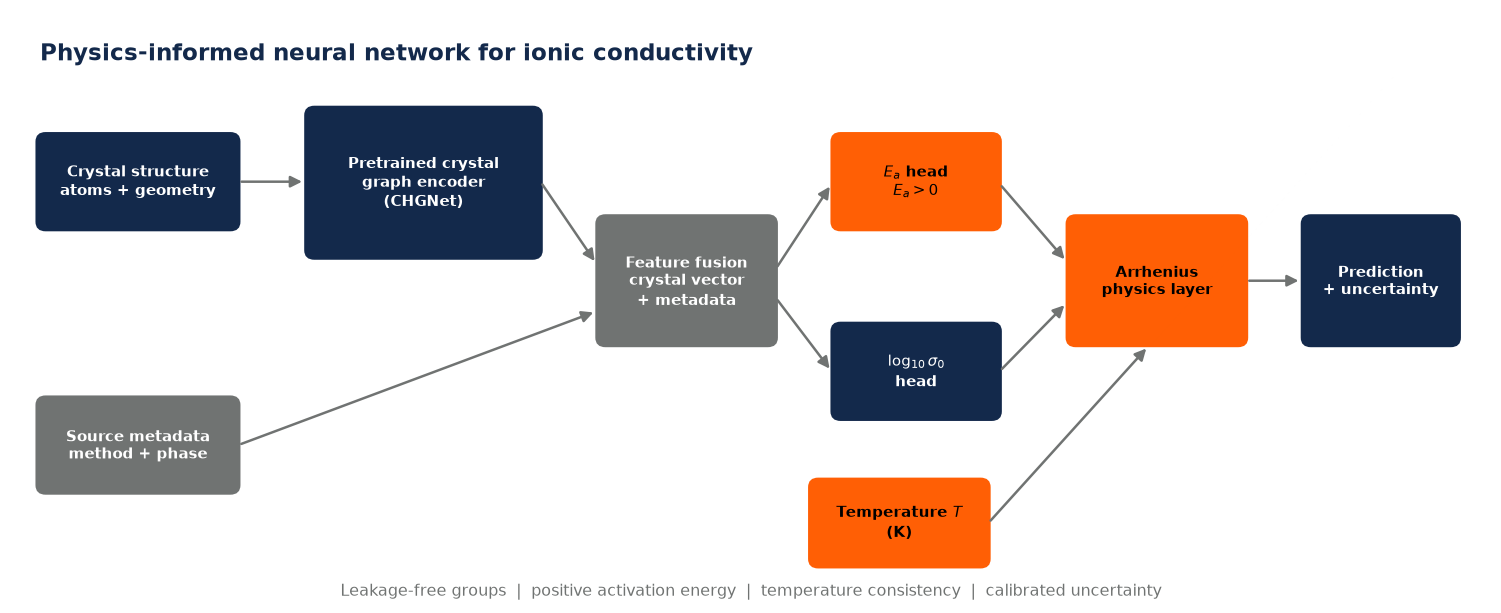

In [4]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch


def architecture_box(axis, xy, width, height, text, facecolor, textcolor="white"):
    box = FancyBboxPatch(
        xy, width, height,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.4, edgecolor=facecolor, facecolor=facecolor,
    )
    axis.add_patch(box)
    axis.text(
        xy[0] + width / 2, xy[1] + height / 2, text,
        ha="center", va="center", color=textcolor,
        fontsize=9.2, fontweight="bold", linespacing=1.22,
    )


def architecture_arrow(axis, start, end):
    axis.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=14,
        linewidth=1.5, color=ILLINI_STORM,
        connectionstyle="arc3,rad=0.0",
    ))


fig, axis = plt.subplots(figsize=(12.4, 5.0), constrained_layout=True)
axis.set_xlim(0, 13.2)
axis.set_ylim(0, 5.6)
axis.axis("off")

axis.text(
    0.25, 5.3, "Physics-informed neural network for ionic conductivity",
    color=ILLINI_BLUE, fontsize=14, fontweight="bold", va="top",
)

architecture_box(axis, (0.25, 3.55), 1.75, 0.86, "Crystal structure\natoms + geometry", ILLINI_BLUE)
architecture_box(axis, (0.25, 1.05), 1.75, 0.86, "Source metadata\nmethod + phase", ILLINI_STORM)
architecture_box(axis, (7.15, 0.35), 1.55, 0.78, "Temperature $T$\n(K)", ILLINI_ORANGE, "black")

architecture_box(axis, (2.65, 3.28), 2.05, 1.38, "Pretrained crystal\ngraph encoder\n(CHGNet)", ILLINI_BLUE)
architecture_box(axis, (5.25, 2.45), 1.55, 1.18, "Feature fusion\ncrystal vector\n+ metadata", ILLINI_STORM)
architecture_box(axis, (7.35, 3.55), 1.45, 0.86, "$E_a$ head\n$E_a>0$", ILLINI_ORANGE, "black")
architecture_box(axis, (7.35, 1.75), 1.45, 0.86, "$\\log_{10}\\sigma_0$\nhead", ILLINI_BLUE)
architecture_box(axis, (9.45, 2.45), 1.55, 1.18, "Arrhenius\nphysics layer", ILLINI_ORANGE, "black")
architecture_box(axis, (11.55, 2.45), 1.35, 1.18, "Prediction\n+ uncertainty", ILLINI_BLUE)

architecture_arrow(axis, (2.02, 3.98), (2.62, 3.98))
architecture_arrow(axis, (4.72, 3.98), (5.22, 3.20))
architecture_arrow(axis, (2.02, 1.48), (5.22, 2.75))
architecture_arrow(axis, (6.82, 3.15), (7.32, 3.96))
architecture_arrow(axis, (6.82, 2.88), (7.32, 2.18))
architecture_arrow(axis, (8.82, 3.96), (9.42, 3.22))
architecture_arrow(axis, (8.82, 2.18), (9.42, 2.83))
architecture_arrow(axis, (8.72, 0.74), (10.15, 2.42))
architecture_arrow(axis, (11.02, 3.04), (11.52, 3.04))

axis.text(
    6.6, 0.05,
    "Leakage-free groups  |  positive activation energy  |  "
    "temperature consistency  |  calibrated uncertainty",
    color=ILLINI_STORM, fontsize=9.3, ha="center",
)

save_report_figure(fig, "figure_01_physics_informed_conductivity_model.png")
plt.show()


**Figure 1.** Long-term PI-ACGNN workflow. The crystal graph encoder learns a structural representation, which is fused with documented non-outcome metadata. Separate neural heads estimate a positive activation energy and conductivity prefactor; the Arrhenius layer combines them with temperature to predict log conductivity, while the ensemble reports uncertainty. The room-temperature conductivity head can be trained first, but the Arrhenius heads remain gated until multi-temperature measurements make their latent parameters identifiable.


## 4. Label normalization and acceptance checks

Every source value must retain its original value and unit. The normalization step creates new canonical columns rather than overwriting source data.

Accepted conductivity units in the first ingestion pass are S/cm, mS/cm, µS/cm, S/m, and mS/m. Resistivity values must be identified and converted separately using $\sigma=1/\rho$; they must never be passed to the conductivity converter as if they were conductivity.

In [5]:
UNIT_TO_S_CM = {
    "S/cm": 1.0,
    "mS/cm": 1e-3,
    "uS/cm": 1e-6,
    "µS/cm": 1e-6,
    "S/m": 1e-2,
    "mS/m": 1e-5,
}

REQUIRED_COLUMNS = [row[0] for row in DATA_SCHEMA if row[3]]


def conductivity_to_s_cm(value: float, unit: str) -> float:
    # Convert a positive conductivity value to S/cm.
    if unit not in UNIT_TO_S_CM:
        raise ValueError(f"Unsupported conductivity unit: {unit!r}")
    value = float(value)
    if not np.isfinite(value) or value <= 0:
        raise ValueError("Conductivity must be finite and strictly positive.")
    return value * UNIT_TO_S_CM[unit]


def material_group_key(row: pd.Series) -> str:
    # Keep polymorphs and repeated temperatures together during validation.
    for column in ("material_key", "mp_id", "structure_id"):
        value = row.get(column)
        if pd.notna(value) and str(value).strip():
            return str(value).strip()
    return f"{row.get('formula', 'unknown')}|{row.get('phase', 'unknown')}"


def prepare_conductivity_labels(frame: pd.DataFrame) -> pd.DataFrame:
    # Validate source labels and create canonical ML columns.
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise KeyError(f"Missing required source columns: {missing}")

    prepared = frame.copy()
    prepared["sigma_S_cm"] = [
        conductivity_to_s_cm(value, unit)
        for value, unit in zip(
            prepared["conductivity_value"],
            prepared["conductivity_unit"],
        )
    ]
    prepared["temperature_K"] = pd.to_numeric(
        prepared["temperature_K"], errors="raise"
    )
    if not prepared["temperature_K"].between(100, 2000).all():
        raise ValueError("Review temperatures outside the broad 100–2000 K audit range.")
    if not prepared["mobile_ion"].eq(MOBILE_ION).all():
        raise ValueError("Model v1 accepts Li-ion records only.")
    if not prepared["conductivity_type"].str.lower().eq("ionic").all():
        raise ValueError("Non-ionic or ambiguous conductivity records must be separated.")

    prepared[TARGET_COLUMN] = np.log10(prepared["sigma_S_cm"])
    prepared["group_material"] = prepared.apply(material_group_key, axis=1)
    return prepared


intake_template = pd.DataFrame(columns=[row[0] for row in DATA_SCHEMA])
INTAKE_TEMPLATE_PATH = ROOT / "data/processed/ionic_conductivity_intake_template.csv"
INTAKE_TEMPLATE_PATH.parent.mkdir(parents=True, exist_ok=True)
intake_template.to_csv(INTAKE_TEMPLATE_PATH, index=False)
display(intake_template)
print("Saved Day 2 intake template:", INTAKE_TEMPLATE_PATH)

,record_id,material_key,mp_id,formula,chemsys,structure_id,phase,mobile_ion,material_class,conductivity_value,conductivity_unit,temperature_K,conductivity_type,label_origin,measurement_method,uncertainty,reference,notes


Saved Day 2 intake template: /Users/zhy/Downloads/battery_ml_starter/data/processed/ionic_conductivity_intake_template.csv


## 5. Leakage-free validation contract

### Required splitting rules

1. All temperatures, repeat measurements, and methods for one resolved material remain in the same fold through `group_material`.
2. The final generalization test holds out complete `chemsys` groups when the dataset is large enough.
3. Imputation, scaling, encoding, feature selection, and tuning are fitted only on training folds.
4. Duplicate literature records are resolved before splitting, not after.

### Variables excluded from the initial feature set

- Conductivity at another temperature for the same material
- Activation energy fitted from the same conductivity measurements
- Arrhenius intercept fitted from the same measurements
- Any manually assigned high/low-conductivity label
- Material identifiers or source identifiers
- Post hoc variables calculated using the target

Migration barriers or defect energies may later be evaluated in a separate enhanced model, but they will not be mixed into the composition-and-structure baseline without a clear availability and cost definition.

### Planned metrics

- MAE and RMSE in $\log_{10}(\mathrm{S/cm})$
- $R^2$
- Multiplicative error factor, $10^{\mathrm{MAE}}$
- Bootstrap confidence intervals grouped by material or chemical system
- Error by temperature range, chemical family, label origin, and applicability domain

In [6]:
PROJECT_CONTRACT = pd.Series(
    {
        "target": TARGET_COLUMN,
        "canonical_unit": "S/cm",
        "reference_temperature_K": REFERENCE_TEMPERATURE_K,
        "mobile_ion": MOBILE_ION,
        "material_scope": MATERIAL_SCOPE,
        "row_definition": "one resolved material-phase/condition record",
        "primary_group": "linked material-or-DOI component",
        "official_holdout": "OBELiX test split",
        "strong_holdout_group": "chemsys",
        "label_source": "OBELiX experimental room-temperature conductivity",
        "next_action": "audit labels and structure coverage before neural-network training",
    },
    name="project decision",
)
display(PROJECT_CONTRACT.to_frame())


,project decision
target,log10_sigma_S_cm
canonical_unit,S/cm
reference_temperature_K,298.15
mobile_ion,Li
material_scope,inorganic solid-state lithium-ion conductor
row_definition,one resolved material-phase/condition record
primary_group,linked material-or-DOI component
official_holdout,OBELiX test split
strong_holdout_group,chemsys
label_source,OBELiX experimental room-temperature conductivity


## 6. Figure standard for the ML project

All analytical figures will follow the supplied report layout and the official UIUC brand palette: Illini Blue (`#13294B`) and Illini Orange (`#FF5F05`) are dominant, with Storm gray used only for neutral baselines. Figures use a white background, bold panel labels, units on every quantitative axis, reference lines where decisions depend on a threshold or ideal value, legends outside dense data regions, and a complete caption stating the comparison and sample context. Figures are saved as 300-dpi PNG files in `figures/` with stable descriptive names.

## 7. Foundation checkpoint

The target, scope, units, staged neural architecture, and leakage rules are fixed. Materials Project remains the candidate-structure source for later screening, while conductivity supervision comes from a separately cited experimental dataset.

The next section imports OBELiX, preserves its official train/test split and DOI provenance, excludes censored values from exact-label regression, quantifies repeated-measurement variability, and determines which neural-network stages are currently supported by the data.


## 8. Literature-backed conductivity dataset

The first supervised dataset is [OBELiX](https://doi.org/10.1039/d5dd00441a), a domain-expert-curated collection of 599 synthesized lithium solid electrolytes with experimental room-temperature ionic conductivity, composition, space group, lattice parameters, source DOI, and 321 associated CIF structures. The official repository distributes the data under CC BY 4.0 and provides a train/test split designed to keep shared compositions and publications together.

This notebook uses the official full, train, and test CSV files from the [NRC-Mila repository](https://github.com/NRC-Mila/OBELiX) at upstream revision `4eaac889809dd489e3bae468c45d5c0e02b9147a`. Source hashes are checked before processing.

### Acceptance rules

- Preserve every original label string and source DOI.
- Treat values reported as “less than” a limit as **censored**, not as exact regression labels.
- Standardize the paper's room-temperature values to a nominal 298.15 K while marking that the exact measurement temperature is unavailable per row.
- Preserve direct, close-match, and unavailable structure categories.
- Keep records linked by composition or DOI in one cross-validation group.
- Retain the authors' official split as the primary held-out benchmark.


In [7]:
from hashlib import sha256

from pymatgen.core import Composition

OBELIX_SOURCE_REVISION = "4eaac889809dd489e3bae468c45d5c0e02b9147a"
OBELIX_PATHS = {
    "all": ROOT / "data/raw/obelix_all.csv",
    "train": ROOT / "data/raw/obelix_train.csv",
    "test": ROOT / "data/raw/obelix_test.csv",
}
OBELIX_SHA256 = {
    "all": "54f6265ef84d16a919d08c6815f14b0fd7465fa00090bee2511c16c042e57f3c",
    "train": "01d87779862807e24bc45bb2c759852f892390b99f9340f13906c54805aa8776",
    "test": "b2c266eb74e22f403743d52959bea7c43b1531a850994870a70dd909200e5297",
}


def file_sha256(path: Path) -> str:
    digest = sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


source_hashes = {name: file_sha256(path) for name, path in OBELIX_PATHS.items()}
assert source_hashes == OBELIX_SHA256, "OBELiX source file hash mismatch."

obelix = pd.read_csv(OBELIX_PATHS["all"])
train_ids = set(pd.read_csv(OBELIX_PATHS["train"])["ID"])
test_ids = set(pd.read_csv(OBELIX_PATHS["test"])["ID"])
assert train_ids.isdisjoint(test_ids)
assert train_ids | test_ids == set(obelix["ID"])
assert not obelix["ID"].duplicated().any()


def composition_metadata(formula: str) -> tuple[str, str]:
    # OBELiX has one hydrate formula containing an asterisk separator.
    composition = Composition(str(formula).replace("*", ""))
    normalized = composition.alphabetical_formula.replace(" ", "")
    return normalized, composition.chemical_system


composition_info = obelix["Reduced Composition"].map(composition_metadata)
obelix["normalized_formula"] = composition_info.map(lambda item: item[0])
obelix["chemsys"] = composition_info.map(lambda item: item[1])
obelix["material_key"] = (
    obelix["normalized_formula"]
    + "|SG"
    + obelix["Space group #"].astype("Int64").astype(str)
)

source_label = obelix["Ionic conductivity (S cm-1)"].astype("string").str.strip()
is_censored = source_label.str.startswith("<", na=False)
numeric_label = pd.to_numeric(
    source_label.str.replace("<", "", regex=False), errors="coerce"
)
label_status = np.select(
    [is_censored, numeric_label.gt(0)],
    ["censored_upper_bound", "exact"],
    default="missing_or_invalid",
)

has_cif = obelix["Cif ID"].astype("string").str.lower().isin(["done", "available"])
is_close_match = (
    obelix["close match"].astype("string").str.lower().eq("yes").fillna(False)
)
structure_match = np.select(
    [is_close_match.to_numpy(dtype=bool), has_cif.to_numpy(dtype=bool)],
    ["close-match CIF", "matched CIF"],
    default="no CIF",
)
source_split = np.where(obelix["ID"].isin(train_ids), "train", "test")

standardized = pd.DataFrame({
    "record_id": "OBELIX:" + obelix["ID"].astype(str),
    "material_key": obelix["material_key"],
    "mp_id": pd.NA,
    "formula": obelix["Reduced Composition"],
    "chemsys": obelix["chemsys"],
    "structure_id": np.where(has_cif, "OBELIX:" + obelix["ID"].astype(str), pd.NA),
    "phase": obelix["Space group"],
    "mobile_ion": MOBILE_ION,
    "material_class": obelix["Family"].fillna("unclassified solid electrolyte"),
    "conductivity_value": numeric_label,
    "conductivity_unit": "S/cm",
    "temperature_K": REFERENCE_TEMPERATURE_K,
    "conductivity_type": "ionic",
    "label_origin": "experimental",
    "measurement_method": pd.NA,
    "uncertainty": np.nan,
    "reference": obelix["DOI"],
    "notes": obelix["note"],
    "source_dataset": "OBELiX",
    "source_record_id": obelix["ID"],
    "source_split": source_split,
    "source_label_text": source_label,
    "label_status": label_status,
    "temperature_is_nominal": True,
    "space_group_number": obelix["Space group #"],
    "lattice_a_A": obelix["a"],
    "lattice_b_A": obelix["b"],
    "lattice_c_A": obelix["c"],
    "alpha_deg": obelix["alpha"],
    "beta_deg": obelix["beta"],
    "gamma_deg": obelix["gamma"],
    "cif_status": obelix["Cif ID"],
    "structure_match": structure_match,
})

exact_mask = standardized["label_status"].eq("exact")
clean_obelix = prepare_conductivity_labels(standardized.loc[exact_mask].copy())
assert np.isfinite(clean_obelix[TARGET_COLUMN]).all()
assert clean_obelix["record_id"].is_unique


In [8]:
def split_dois(value) -> list[str]:
    if pd.isna(value):
        return []
    return [
        token.strip().lower()
        for token in str(value).split("|")
        if token.strip()
    ]


def build_linked_groups(frame: pd.DataFrame) -> pd.Series:
    # Union-find links rows that share either material identity or source DOI.
    parent = list(range(len(frame)))

    def find(index):
        while parent[index] != index:
            parent[index] = parent[parent[index]]
            index = parent[index]
        return index

    def union(left, right):
        root_left, root_right = find(left), find(right)
        if root_left != root_right:
            parent[root_right] = root_left

    token_owner = {}
    for position, (_, row) in enumerate(frame.iterrows()):
        tokens = [f"material::{row['material_key']}"]
        tokens.extend(f"doi::{doi}" for doi in split_dois(row["reference"]))
        for token in tokens:
            if token in token_owner:
                union(position, token_owner[token])
            else:
                token_owner[token] = position

    roots = [find(position) for position in range(len(frame))]
    labels = {root: f"linked_{number:04d}" for number, root in enumerate(sorted(set(roots)), 1)}
    return pd.Series([labels[root] for root in roots], index=frame.index)


clean_obelix["group_linked"] = build_linked_groups(clean_obelix)
cross_split_groups = (
    clean_obelix.groupby("group_linked")["source_split"].nunique().gt(1).sum()
)
assert cross_split_groups == 0, "Official split leaks a linked composition/DOI group."

material_sizes = clean_obelix.groupby("group_material").size()
repeated_materials = material_sizes[material_sizes.ge(2)].index
repeat_mask = clean_obelix["group_material"].isin(repeated_materials)
repeat_abs_deviation = (
    clean_obelix.loc[repeat_mask, TARGET_COLUMN]
    - clean_obelix.loc[repeat_mask].groupby("group_material")[TARGET_COLUMN].transform("median")
).abs()

OUTPUT_CONDUCTIVITY_PATH = ROOT / "data/processed/obelix_conductivity_clean.csv"
OUTPUT_CONDUCTIVITY_PATH.parent.mkdir(parents=True, exist_ok=True)
clean_obelix.to_csv(OUTPUT_CONDUCTIVITY_PATH, index=False)

obelix_audit = pd.Series({
    "source_rows": len(standardized),
    "exact_positive_labels": len(clean_obelix),
    "censored_upper_bounds_preserved_but_excluded": int((label_status == "censored_upper_bound").sum()),
    "exact_labels_with_any_CIF": int(clean_obelix["structure_match"].ne("no CIF").sum()),
    "exact_labels_with_directly_matched_CIF": int(clean_obelix["structure_match"].eq("matched CIF").sum()),
    "unique_material_groups": clean_obelix["group_material"].nunique(),
    "repeated_material_groups": len(repeated_materials),
    "rows_in_repeated_material_groups": int(repeat_mask.sum()),
    "observed_repeat_mean_absolute_deviation_dex": repeat_abs_deviation.mean(),
    "unique_chemical_systems": clean_obelix["chemsys"].nunique(),
    "linked_groups_crossing_official_split": int(cross_split_groups),
}, name="value")

split_summary = clean_obelix.groupby("source_split").agg(
    exact_labels=("record_id", "size"),
    material_groups=("group_material", "nunique"),
    linked_groups=("group_linked", "nunique"),
    labels_with_CIF=("structure_match", lambda values: values.ne("no CIF").sum()),
    median_log10_sigma=(TARGET_COLUMN, "median"),
).reindex(["train", "test"])

display(pd.Series(source_hashes, name="SHA-256").to_frame())
display(obelix_audit.to_frame())
display(split_summary)
print("Saved cleaned OBELiX table:", OUTPUT_CONDUCTIVITY_PATH)


,SHA-256
all,54f6265ef84d16a919d08c6815f14b0fd7465fa00090be...
train,01d87779862807e24bc45bb2c759852f892390b99f9340...
test,b2c266eb74e22f403743d52959bea7c43b1531a8509948...


,value
source_rows,599.000000
exact_positive_labels,562.000000
censored_upper_bounds_preserved_but_excluded,37.000000
exact_labels_with_any_CIF,287.000000
exact_labels_with_directly_matched_CIF,226.000000
unique_material_groups,487.000000
repeated_material_groups,48.000000
rows_in_repeated_material_groups,123.000000
observed_repeat_mean_absolute_deviation_dex,0.408245
unique_chemical_systems,192.000000


,exact_labels,material_groups,linked_groups,labels_with_CIF,median_log10_sigma
source_split,,,,,
train,449,377,110,226,-4.084073
test,113,110,40,61,-4.124939


Saved cleaned OBELiX table: /Users/zhy/Downloads/battery_ml_starter/data/processed/obelix_conductivity_clean.csv


### Audit interpretation

The exact-label regression table contains 562 records; 37 upper-bound values remain in the raw source files but are excluded from ordinary regression. Only 287 exact-label records have an associated CIF and 61 of those are close structural matches, so geometric modeling is substantially more data-limited than composition modeling.

Repeated measurements are not silently averaged. They remain in the table, share a validation group, and expose experimental variability. After canonicalizing equivalent formula strings, the current snapshot contains 123 exact measurements in 48 repeated material groups. Their observed mean absolute deviation from each material's median is 0.41 dex, consistent with the 0.41 dex value reported by the OBELiX authors; this becomes a practical warning against implausibly low test errors.


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_02_obelix_data_audit.png


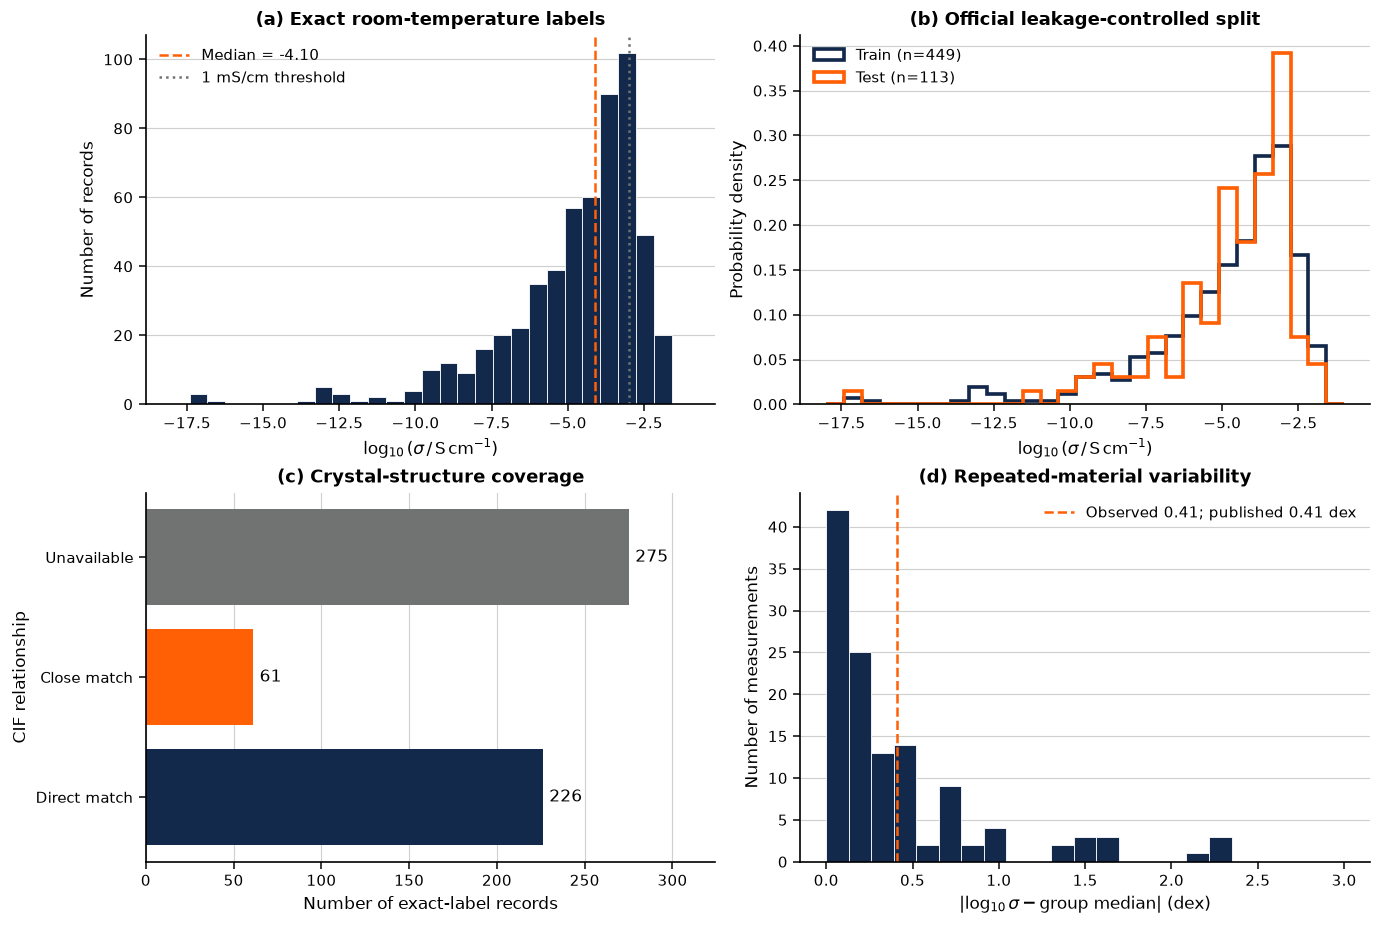

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11.4, 7.6), constrained_layout=True)

# (a) Exact target distribution
target_values = clean_obelix[TARGET_COLUMN]
bins = np.linspace(np.floor(target_values.min()), np.ceil(target_values.max()), 30)
axes[0, 0].hist(target_values, bins=bins, color=ILLINI_BLUE, edgecolor="white", linewidth=0.5)
axes[0, 0].axvline(target_values.median(), color=ILLINI_ORANGE, linestyle="--",
                   label=f"Median = {target_values.median():.2f}")
axes[0, 0].axvline(-3, color=ILLINI_STORM, linestyle=":", label="1 mS/cm threshold")
axes[0, 0].set_title("(a) Exact room-temperature labels")
axes[0, 0].set_xlabel(r"$\log_{10}(\sigma\,/\,\mathrm{S\,cm^{-1}})$")
axes[0, 0].set_ylabel("Number of records")
axes[0, 0].legend(loc="upper left")
finish_axis(axes[0, 0], "y")

# (b) Official split distribution check
for split, color in [("train", ILLINI_BLUE), ("test", ILLINI_ORANGE)]:
    values = clean_obelix.loc[clean_obelix["source_split"].eq(split), TARGET_COLUMN]
    axes[0, 1].hist(values, bins=bins, density=True, histtype="step", linewidth=2.2,
                    color=color, label=f"{split.title()} (n={len(values)})")
axes[0, 1].set_title("(b) Official leakage-controlled split")
axes[0, 1].set_xlabel(r"$\log_{10}(\sigma\,/\,\mathrm{S\,cm^{-1}})$")
axes[0, 1].set_ylabel("Probability density")
axes[0, 1].legend(loc="upper left")
finish_axis(axes[0, 1], "y")

# (c) Structure coverage for exact labels
structure_order = ["matched CIF", "close-match CIF", "no CIF"]
structure_counts = clean_obelix["structure_match"].value_counts().reindex(structure_order)
bars = axes[1, 0].barh(
    ["Direct match", "Close match", "Unavailable"], structure_counts,
    color=[ILLINI_BLUE, ILLINI_ORANGE, ILLINI_STORM],
)
axes[1, 0].bar_label(bars, padding=4)
axes[1, 0].set_xlim(0, structure_counts.max() * 1.18)
axes[1, 0].set_title("(c) Crystal-structure coverage")
axes[1, 0].set_xlabel("Number of exact-label records")
axes[1, 0].set_ylabel("CIF relationship")
finish_axis(axes[1, 0], "x")

# (d) Experimental repeatability
repeat_bins = np.linspace(0, max(3.0, repeat_abs_deviation.max()), 24)
axes[1, 1].hist(repeat_abs_deviation, bins=repeat_bins, color=ILLINI_BLUE,
                edgecolor="white", linewidth=0.5)
axes[1, 1].axvline(repeat_abs_deviation.mean(), color=ILLINI_ORANGE, linestyle="--",
                   label=f"Observed {repeat_abs_deviation.mean():.2f}; published 0.41 dex")
axes[1, 1].set_title("(d) Repeated-material variability")
axes[1, 1].set_xlabel(r"$|\log_{10}\sigma-\mathrm{group\ median}|$ (dex)")
axes[1, 1].set_ylabel("Number of measurements")
axes[1, 1].legend(loc="upper right")
finish_axis(axes[1, 1], "y")

save_report_figure(fig, "figure_02_obelix_data_audit.png")
plt.show()


**Figure 2.** OBELiX ingestion and quality audit. (a) Distribution of 562 exact experimental room-temperature conductivity labels; the gray reference denotes the commonly used 1 mS/cm fast-conductor threshold. (b) The authors' official train (449) and test (113) subsets retain similar target distributions while preventing shared-composition or shared-publication leakage. (c) Only 287 exact-label entries have a CIF, including 61 close matches. (d) After canonicalizing equivalent formula strings, the current source snapshot contains 123 exact measurements in 48 repeated material groups; their mean absolute deviation from the group median is 0.41 dex, consistent with the published experimental floor.


## 9. Identifiability gate for the physics-informed model

OBELiX provides one nominal room-temperature target per record. At a single temperature $T_0$,

$$
y(T_0)=\log_{10}\sigma_0-\frac{E_a}{k_{\mathrm B}T_0\ln 10},
$$

so infinitely many $(\sigma_0,E_a)$ pairs produce the same $y(T_0)$. Separate activation-energy and prefactor heads are therefore **not identifiable from OBELiX alone**. Fitting them now would add physical-looking parameters without experimental support.

The defensible sequence is:

1. Predict $\log_{10}\sigma_{\mathrm{RT}}$ with a composition MLP and transfer-learned crystal GNN.
2. Calibrate uncertainty against the held-out OBELiX test set and the repeated-measurement noise scale.
3. Add multi-temperature conductivity series with material identities and measurement conditions.
4. Only then fit the Arrhenius layer and test whether its constraints improve extrapolation.


In [10]:
MODEL_READINESS = pd.DataFrame([
    {
        "model stage": "Composition-only MLP",
        "usable exact labels": len(clean_obelix),
        "status": "ready for grouped baseline",
        "decision": "train first",
    },
    {
        "model stage": "Room-temperature crystal GNN",
        "usable exact labels": int(clean_obelix["structure_match"].ne("no CIF").sum()),
        "status": "small-data transfer learning only",
        "decision": "freeze encoder initially",
    },
    {
        "model stage": "Direct-match crystal GNN sensitivity check",
        "usable exact labels": int(clean_obelix["structure_match"].eq("matched CIF").sum()),
        "status": "higher-confidence structure subset",
        "decision": "compare with all-CIF subset",
    },
    {
        "model stage": "Arrhenius PI-ACGNN",
        "usable exact labels": 0,
        "status": "not identifiable from room-temperature-only data",
        "decision": "wait for multi-temperature labels",
    },
])
display(MODEL_READINESS)


,model stage,usable exact labels,status,decision
0,Composition-only MLP,562,ready for grouped baseline,train first
1,Room-temperature crystal GNN,287,small-data transfer learning only,freeze encoder initially
2,Direct-match crystal GNN sensitivity check,226,higher-confidence structure subset,compare with all-CIF subset
3,Arrhenius PI-ACGNN,0,not identifiable from room-temperature-only data,wait for multi-temperature labels


## 10. Neural-baseline decision rule

The first trainable model is a composition-only MLP on the official OBELiX split, with linked material/DOI groups retained during cross-validation. The model must beat a training-median reference on the untouched test set before it is allowed to rank Materials Project candidates. This gate prevents a complex-looking neural network from being used when it has not demonstrated predictive value.


## 11. Composition-only neural baseline

The OBELiX study found that small-data neural and graph models can overfit and that cross-validation performance may not transfer to its carefully constructed test split. Our baseline therefore adds four safeguards:

1. Element vocabulary is learned from the training set only, with an explicit unknown-element fraction.
2. Both inputs and the log-conductivity target are scaled inside each training fold.
3. Cross-validation groups all records connected by composition or source DOI.
4. Predictions average multiple neural-network initializations and must beat a training-median reference before Materials Project screening is permitted.

The MLP uses atom fractions plus compact stoichiometric and elemental-property summaries. These are composition descriptors—not structural or simulation-derived inputs—so this model is a conservative first neural baseline rather than the final PI-ACGNN.


In [11]:
import warnings

from pymatgen.core import Element
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 432
MODEL_TARGET = TARGET_COLUMN

model_data = clean_obelix.copy()
model_train = model_data.loc[model_data["source_split"].eq("train")].copy()
model_test = model_data.loc[model_data["source_split"].eq("test")].copy()


def parse_composition(formula):
    return Composition(str(formula).replace("*", ""))


train_compositions = model_train["formula"].map(parse_composition)
ELEMENT_VOCAB = sorted({str(element) for composition in train_compositions for element in composition.elements})


def safe_element_property(element, name):
    value = getattr(element, name, None)
    try:
        return float(value) if value is not None else np.nan
    except (TypeError, ValueError):
        return np.nan


def composition_features(formulas: pd.Series) -> pd.DataFrame:
    rows = []
    for formula in formulas:
        composition = parse_composition(formula)
        fractions = composition.fractional_composition.get_el_amt_dict()
        fraction_values = np.array(list(fractions.values()), dtype=float)
        row = {
            f"frac_{element}": fractions.get(element, 0.0)
            for element in ELEMENT_VOCAB
        }
        row["unknown_element_fraction"] = sum(
            fraction for element, fraction in fractions.items()
            if element not in ELEMENT_VOCAB
        )
        row["n_elements"] = len(fractions)
        row["li_fraction"] = fractions.get("Li", 0.0)
        row["composition_entropy"] = float(
            -(fraction_values * np.log(fraction_values)).sum()
        )
        row["max_element_fraction"] = float(fraction_values.max())
        row["min_element_fraction"] = float(fraction_values.min())

        for property_name, output_name in [
            ("Z", "mean_atomic_number"),
            ("atomic_mass", "mean_atomic_mass"),
            ("X", "mean_electronegativity"),
            ("row", "mean_periodic_row"),
            ("group", "mean_periodic_group"),
        ]:
            numerator = denominator = 0.0
            property_values = []
            for symbol, fraction in fractions.items():
                value = safe_element_property(Element(symbol), property_name)
                if np.isfinite(value):
                    numerator += fraction * value
                    denominator += fraction
                    property_values.append(value)
            row[output_name] = numerator / denominator if denominator else 0.0
            if property_name == "X":
                row["electronegativity_range"] = (
                    max(property_values) - min(property_values)
                    if property_values else 0.0
                )
        rows.append(row)
    return pd.DataFrame(rows, index=formulas.index)


X_train = composition_features(model_train["formula"])
X_test = composition_features(model_test["formula"])
y_train = model_train[MODEL_TARGET]
y_test = model_test[MODEL_TARGET]
cv_groups = model_train["group_linked"]

print(
    f"Training rows: {len(X_train)} | test rows: {len(X_test)} | "
    f"features: {X_train.shape[1]} | training elements: {len(ELEMENT_VOCAB)}"
)


Training rows: 449 | test rows: 113 | features: 64 | training elements: 52


In [12]:
MLP_CONFIGS = [
    {"hidden_layer_sizes": (16,), "alpha": 1.0},
    {"hidden_layer_sizes": (32,), "alpha": 1.0},
    {"hidden_layer_sizes": (64, 32), "alpha": 1.0},
    {"hidden_layer_sizes": (32,), "alpha": 10.0},
    {"hidden_layer_sizes": (64, 32), "alpha": 10.0},
    {"hidden_layer_sizes": (64, 32), "alpha": 100.0},
]
TUNING_SEEDS = [17, 43]


def config_label(config):
    layers = "×".join(str(width) for width in config["hidden_layer_sizes"])
    return f"{layers}; α={config['alpha']:g}"


def build_mlp(config, seed):
    feature_model = Pipeline([
        ("scale", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=config["hidden_layer_sizes"],
            alpha=config["alpha"],
            solver="lbfgs",
            activation="relu",
            max_iter=2000,
            tol=1e-5,
            random_state=seed,
        )),
    ])
    return TransformedTargetRegressor(
        regressor=feature_model,
        transformer=StandardScaler(),
    )


warnings.filterwarnings("ignore", category=ConvergenceWarning)
grouped_cv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(grouped_cv.split(X_train, y_train, cv_groups))

cv_rows = []
for config_index, config in enumerate(MLP_CONFIGS):
    for fold, (fit_index, validation_index) in enumerate(cv_splits, start=1):
        fold_predictions = []
        for seed in TUNING_SEEDS:
            fold_model = build_mlp(config, seed)
            fold_model.fit(X_train.iloc[fit_index], y_train.iloc[fit_index])
            fold_predictions.append(fold_model.predict(X_train.iloc[validation_index]))
        prediction = np.mean(fold_predictions, axis=0)
        truth = y_train.iloc[validation_index]
        cv_rows.append({
            "config_index": config_index,
            "config": config_label(config),
            "fold": fold,
            "validation_rows": len(validation_index),
            "validation_groups": cv_groups.iloc[validation_index].nunique(),
            "MAE_dex": mean_absolute_error(truth, prediction),
            "RMSE_dex": np.sqrt(mean_squared_error(truth, prediction)),
            "R2": r2_score(truth, prediction),
        })

mlp_cv_results = pd.DataFrame(cv_rows)
mlp_cv_summary = mlp_cv_results.groupby(["config_index", "config"]).agg(
    mean_MAE_dex=("MAE_dex", "mean"),
    std_MAE_dex=("MAE_dex", "std"),
    mean_RMSE_dex=("RMSE_dex", "mean"),
    mean_R2=("R2", "mean"),
).reset_index()

BEST_CONFIG_INDEX = int(mlp_cv_summary.loc[mlp_cv_summary["mean_MAE_dex"].idxmin(), "config_index"])
BEST_MLP_CONFIG = MLP_CONFIGS[BEST_CONFIG_INDEX]
mlp_cv_summary["selected"] = mlp_cv_summary["config_index"].eq(BEST_CONFIG_INDEX)

MLP_CV_PATH = ROOT / "data/processed/obelix_mlp_cv_results.csv"
mlp_cv_results.to_csv(MLP_CV_PATH, index=False)
display(mlp_cv_summary.style.format({
    "mean_MAE_dex": "{:.3f}", "std_MAE_dex": "{:.3f}",
    "mean_RMSE_dex": "{:.3f}", "mean_R2": "{:.3f}",
}))
print("Selected configuration:", config_label(BEST_MLP_CONFIG))


,config_index,config,mean_MAE_dex,std_MAE_dex,mean_RMSE_dex,mean_R2,selected
0,0,16; α=1,1.512,0.487,2.323,-0.047,False
1,1,32; α=1,1.501,0.556,2.275,-0.003,False
2,2,64×32; α=1,1.538,0.569,2.290,-0.010,False
3,3,32; α=10,1.467,0.606,2.095,0.153,True
4,4,64×32; α=10,1.478,0.539,2.102,0.147,False
5,5,64×32; α=100,1.729,0.466,2.358,-0.080,False


Selected configuration: 32; α=10


In [13]:
FINAL_ENSEMBLE_SEEDS = [11, 23, 37, 53, 71, 89, 107, 131, 149, 173]
final_models = []
test_prediction_members = []
for seed in FINAL_ENSEMBLE_SEEDS:
    model = build_mlp(BEST_MLP_CONFIG, seed)
    model.fit(X_train, y_train)
    final_models.append(model)
    test_prediction_members.append(model.predict(X_test))

test_prediction_matrix = np.vstack(test_prediction_members)
test_prediction = test_prediction_matrix.mean(axis=0)
test_model_std = test_prediction_matrix.std(axis=0, ddof=1)
test_absolute_error = np.abs(y_test.to_numpy() - test_prediction)

# Grouped out-of-fold residuals calibrate a train-only 90% error interval.
oof_prediction = np.full(len(X_train), np.nan)
for fit_index, validation_index in cv_splits:
    fold_members = []
    for seed in TUNING_SEEDS:
        fold_model = build_mlp(BEST_MLP_CONFIG, seed)
        fold_model.fit(X_train.iloc[fit_index], y_train.iloc[fit_index])
        fold_members.append(fold_model.predict(X_train.iloc[validation_index]))
    oof_prediction[validation_index] = np.mean(fold_members, axis=0)

oof_absolute_error = np.abs(y_train.to_numpy() - oof_prediction)
interval_half_width = float(np.quantile(oof_absolute_error, 0.90, method="higher"))
interval_lower = test_prediction - interval_half_width
interval_upper = test_prediction + interval_half_width
interval_coverage = np.mean(
    (y_test.to_numpy() >= interval_lower) & (y_test.to_numpy() <= interval_upper)
)

# Resample complete linked groups for a chemistry-aware MAE interval.
rng = np.random.default_rng(RANDOM_STATE)
test_group_values = model_test["group_linked"].unique()
group_to_positions = {
    group: np.flatnonzero(model_test["group_linked"].to_numpy() == group)
    for group in test_group_values
}
bootstrap_mae = []
for _ in range(2000):
    sampled_groups = rng.choice(test_group_values, size=len(test_group_values), replace=True)
    positions = np.concatenate([group_to_positions[group] for group in sampled_groups])
    bootstrap_mae.append(mean_absolute_error(
        y_test.to_numpy()[positions], test_prediction[positions]
    ))

mlp_test_mae = mean_absolute_error(y_test, test_prediction)
median_reference_prediction = np.repeat(y_train.median(), len(y_test))
median_reference_mae = mean_absolute_error(y_test, median_reference_prediction)
MODEL_PASSES_SCREENING_GATE = bool(mlp_test_mae < median_reference_mae)

mlp_test_metrics = pd.Series({
    "grouped_CV_MAE_dex": mlp_cv_summary.loc[
        mlp_cv_summary["selected"], "mean_MAE_dex"
    ].iloc[0],
    "test_MAE_dex": mlp_test_mae,
    "test_MAE_group_bootstrap_95pct_low": np.quantile(bootstrap_mae, 0.025),
    "test_MAE_group_bootstrap_95pct_high": np.quantile(bootstrap_mae, 0.975),
    "test_RMSE_dex": np.sqrt(mean_squared_error(y_test, test_prediction)),
    "test_R2": r2_score(y_test, test_prediction),
    "multiplicative_error_factor": 10 ** mlp_test_mae,
    "training_median_reference_MAE_dex": median_reference_mae,
    "mean_ensemble_std_dex": test_model_std.mean(),
    "uncertainty_absolute_error_Spearman": pd.Series(test_model_std).corr(
        pd.Series(test_absolute_error), method="spearman"
    ),
    "train_only_90pct_interval_half_width_dex": interval_half_width,
    "test_interval_coverage": interval_coverage,
    "passes_MP_screening_gate": MODEL_PASSES_SCREENING_GATE,
}, name="value")

mlp_test_predictions = model_test[[
    "record_id", "formula", "chemsys", "group_material", "group_linked",
    "structure_match", MODEL_TARGET,
]].copy()
mlp_test_predictions["predicted_log10_sigma_S_cm"] = test_prediction
mlp_test_predictions["ensemble_std_dex"] = test_model_std
mlp_test_predictions["absolute_error_dex"] = test_absolute_error
mlp_test_predictions["interval90_lower"] = interval_lower
mlp_test_predictions["interval90_upper"] = interval_upper
mlp_test_predictions["interval90_contains_observation"] = (
    (y_test.to_numpy() >= interval_lower) & (y_test.to_numpy() <= interval_upper)
)

MLP_TEST_PATH = ROOT / "data/processed/obelix_mlp_test_predictions.csv"
mlp_test_predictions.to_csv(MLP_TEST_PATH, index=False)
display(mlp_test_metrics.to_frame())
print(
    "Screening decision:",
    "PASS" if MODEL_PASSES_SCREENING_GATE else "FAIL — do not rank MP candidates",
)


,value
grouped_CV_MAE_dex,1.466696
test_MAE_dex,1.661093
test_MAE_group_bootstrap_95pct_low,1.144748
test_MAE_group_bootstrap_95pct_high,2.378701
test_RMSE_dex,2.608982
test_R2,-0.341303
multiplicative_error_factor,45.823959
training_median_reference_MAE_dex,1.550263
mean_ensemble_std_dex,0.262441
uncertainty_absolute_error_Spearman,0.535668


Screening decision: FAIL — do not rank MP candidates


### Baseline result and decision

The selected neural network uses one 32-unit hidden layer with strong $L_2$ regularization ($\alpha=10$). Its linked-group cross-validation MAE is substantially better than the initial unscaled model, but the official held-out test result remains worse than predicting the training median. The negative $R^2$ confirms that this composition-only network has not learned a sufficiently transferable conductivity relation.

This is a useful result, not a failed project step: the performance gate prevents thousands of Materials Project entries from receiving unjustified conductivity rankings. The next model must add information or transfer learning and demonstrate improvement on the same untouched test set.


## 12. Materials Project candidate consultation

Materials Project is used here as an **unlabeled inference and structure source**. Following hierarchical solid-electrolyte screening studies, the broad query retains Li-containing, nonmetallic compounds with 3–6 elements, band gap $\geq1$ eV, and energy above hull $\leq0.05$ eV/atom. These are prescreening criteria, not proof of ionic conduction, electrochemical stability, or synthesizability.

The query uses the official summary endpoint and caches the response. Model applicability is then checked from training-element coverage and standardized nearest-composition distance. Because the neural baseline fails its predictive gate, no MP conductivity ranking is generated even for candidates that fall inside this approximate domain.

Screening references: [holistic Li-conductor screening](https://doi.org/10.1039/C6EE02697D), [ML-assisted solid-conductor discovery](https://doi.org/10.1021/acs.chemmater.8b03272), and the [Materials Project summary API](https://materialsproject.github.io/api/_autosummary/mp_api.client.routes.materials.summary.SummaryRester.html).


In [14]:
MP_CANDIDATE_PATH = ROOT / "data/processed/mp_li_solid_electrolyte_candidates.csv"
REFRESH_MP_CANDIDATES = False


def load_mp_candidate_pool(force_refresh=False):
    if force_refresh:
        api_key = os.getenv("MP_API_KEY")
        if not api_key:
            raise RuntimeError("Add MP_API_KEY to .env before refreshing MP candidates.")
        from mp_api.client import MPRester

        fields = [
            "material_id", "formula_pretty", "chemsys", "elements", "nelements",
            "nsites", "volume", "density", "band_gap", "energy_above_hull",
            "formation_energy_per_atom", "is_metal", "is_stable", "theoretical",
            "deprecated", "symmetry",
        ]
        with MPRester(api_key, use_document_model=False, mute_progress_bars=True) as mpr:
            documents = mpr.materials.summary.search(
                elements=["Li"], num_elements=(3, 6),
                energy_above_hull=(0.0, 0.05), band_gap=(1.0, 20.0),
                is_metal=False, deprecated=False, include_gnome=False,
                all_fields=False, fields=fields, chunk_size=1000,
            )
            database_version = mpr.db_version
        rows = []
        for document in documents:
            symmetry = document.get("symmetry") or {}
            rows.append({
                "material_id": str(document.get("material_id")),
                "formula_pretty": document.get("formula_pretty"),
                "chemsys": document.get("chemsys"),
                "elements": "-".join(sorted(str(e) for e in document.get("elements") or [])),
                "nelements": document.get("nelements"),
                "nsites": document.get("nsites"),
                "volume_A3": document.get("volume"),
                "density_g_cm3": document.get("density"),
                "band_gap_eV": document.get("band_gap"),
                "energy_above_hull_eV_atom": document.get("energy_above_hull"),
                "formation_energy_eV_atom": document.get("formation_energy_per_atom"),
                "is_metal": document.get("is_metal"),
                "is_stable": document.get("is_stable"),
                "theoretical": document.get("theoretical"),
                "deprecated": document.get("deprecated"),
                "crystal_system": symmetry.get("crystal_system"),
                "space_group_symbol": symmetry.get("symbol"),
                "space_group_number": symmetry.get("number"),
                "mp_database_version": database_version,
                "query_energy_above_hull_max_eV_atom": 0.05,
                "query_band_gap_min_eV": 1.0,
            })
        frame = pd.DataFrame(rows).sort_values(
            ["energy_above_hull_eV_atom", "band_gap_eV", "material_id"],
            ascending=[True, False, True],
        ).reset_index(drop=True)
        frame.to_csv(MP_CANDIDATE_PATH, index=False)
        return frame

    if not MP_CANDIDATE_PATH.exists():
        raise FileNotFoundError(
            "MP candidate cache is missing. Configure MP_API_KEY and set "
            "REFRESH_MP_CANDIDATES=True once."
        )
    return pd.read_csv(MP_CANDIDATE_PATH)


mp_candidates = load_mp_candidate_pool(REFRESH_MP_CANDIDATES)
assert mp_candidates["material_id"].is_unique
assert mp_candidates["energy_above_hull_eV_atom"].le(0.05 + 1e-12).all()
assert mp_candidates["band_gap_eV"].ge(1.0 - 1e-12).all()

candidate_features = composition_features(mp_candidates["formula_pretty"])
domain_scaler = StandardScaler().fit(X_train)
scaled_train = domain_scaler.transform(X_train)
scaled_candidates = domain_scaler.transform(candidate_features)

train_neighbor_model = NearestNeighbors(n_neighbors=2).fit(scaled_train)
train_neighbor_distances = train_neighbor_model.kneighbors(scaled_train)[0][:, 1]
DOMAIN_DISTANCE_THRESHOLD = float(np.quantile(train_neighbor_distances, 0.95))

candidate_neighbor_model = NearestNeighbors(n_neighbors=1).fit(scaled_train)
candidate_distances = candidate_neighbor_model.kneighbors(scaled_candidates)[0][:, 0]

mp_domain_audit = mp_candidates.copy()
mp_domain_audit["unknown_element_fraction"] = candidate_features[
    "unknown_element_fraction"
].to_numpy()
mp_domain_audit["nearest_training_distance"] = candidate_distances
mp_domain_audit["domain_distance_threshold"] = DOMAIN_DISTANCE_THRESHOLD
mp_domain_audit["all_elements_seen_in_training"] = mp_domain_audit[
    "unknown_element_fraction"
].le(1e-12)
mp_domain_audit["near_training_composition"] = mp_domain_audit[
    "nearest_training_distance"
].le(DOMAIN_DISTANCE_THRESHOLD)
mp_domain_audit["in_approximate_composition_domain"] = (
    mp_domain_audit["all_elements_seen_in_training"]
    & mp_domain_audit["near_training_composition"]
)
mp_domain_audit["chemical_system_seen_in_training"] = mp_domain_audit[
    "chemsys"
].isin(set(model_train["chemsys"]))
mp_domain_audit["model_performance_gate_passed"] = MODEL_PASSES_SCREENING_GATE
mp_domain_audit["eligible_for_conductivity_ranking"] = (
    mp_domain_audit["in_approximate_composition_domain"]
    & MODEL_PASSES_SCREENING_GATE
)

MP_DOMAIN_PATH = ROOT / "data/processed/mp_li_solid_electrolyte_domain_audit.csv"
mp_domain_audit.to_csv(MP_DOMAIN_PATH, index=False)

mp_funnel = pd.Series({
    "MP prescreen query": len(mp_domain_audit),
    "all elements represented in training": int(mp_domain_audit["all_elements_seen_in_training"].sum()),
    "near training compositions": int(mp_domain_audit["near_training_composition"].sum()),
    "approximate composition domain": int(mp_domain_audit["in_approximate_composition_domain"].sum()),
    "chemical system already seen": int(mp_domain_audit["chemical_system_seen_in_training"].sum()),
    "eligible after model-performance gate": int(mp_domain_audit["eligible_for_conductivity_ranking"].sum()),
}, name="candidate count")
display(mp_funnel.to_frame())
print("MP database version:", mp_domain_audit["mp_database_version"].iloc[0])
print("Saved MP domain audit:", MP_DOMAIN_PATH)


,candidate count
MP prescreen query,5068
all elements represented in training,4341
near training compositions,2531
approximate composition domain,2038
chemical system already seen,534
eligible after model-performance gate,0


MP database version: 2026.09.28
Saved MP domain audit: /Users/zhy/Downloads/battery_ml_starter/data/processed/mp_li_solid_electrolyte_domain_audit.csv


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_03_mlp_and_mp_screening_gate.png


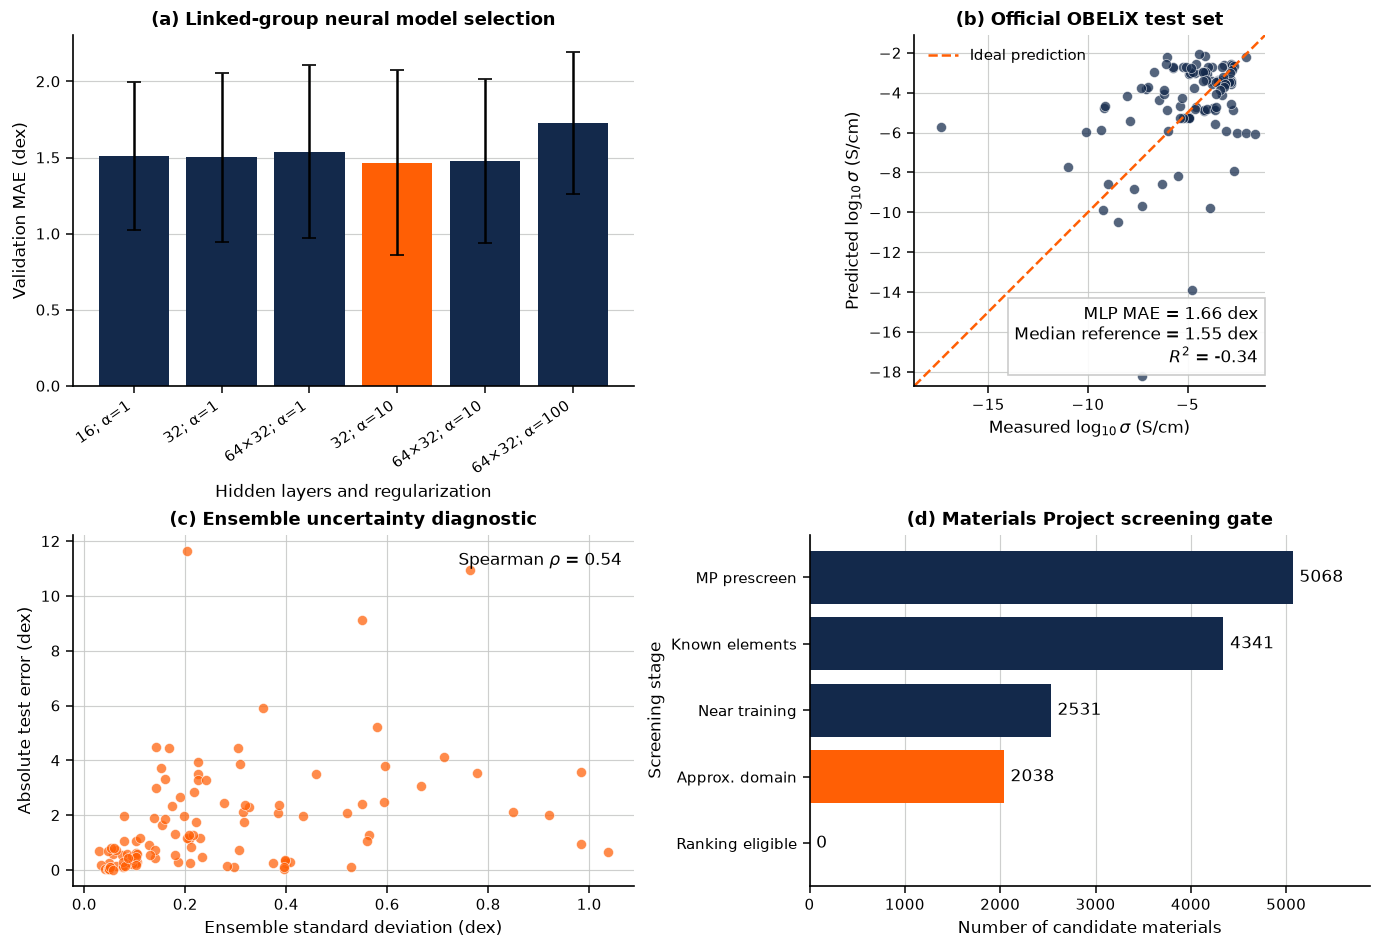

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11.4, 7.8), constrained_layout=True)

# (a) Grouped CV model selection
cv_plot = mlp_cv_summary.sort_values("config_index")
colors = [ILLINI_ORANGE if selected else ILLINI_BLUE for selected in cv_plot["selected"]]
bars = axes[0, 0].bar(
    np.arange(len(cv_plot)), cv_plot["mean_MAE_dex"],
    yerr=cv_plot["std_MAE_dex"], capsize=4, color=colors,
)
axes[0, 0].set_xticks(np.arange(len(cv_plot)), cv_plot["config"], rotation=35, ha="right")
axes[0, 0].set_title("(a) Linked-group neural model selection")
axes[0, 0].set_ylabel("Validation MAE (dex)")
axes[0, 0].set_xlabel("Hidden layers and regularization")
finish_axis(axes[0, 0], "y")

# (b) Official test-set parity
plot_min = min(y_test.min(), test_prediction.min()) - 0.5
plot_max = max(y_test.max(), test_prediction.max()) + 0.5
axes[0, 1].scatter(y_test, test_prediction, color=ILLINI_BLUE, alpha=0.72,
                   edgecolor="white", linewidth=0.4)
axes[0, 1].plot([plot_min, plot_max], [plot_min, plot_max], color=ILLINI_ORANGE,
                linestyle="--", label="Ideal prediction")
axes[0, 1].set_xlim(plot_min, plot_max)
axes[0, 1].set_ylim(plot_min, plot_max)
axes[0, 1].set_aspect("equal", adjustable="box")
axes[0, 1].set_title("(b) Official OBELiX test set")
axes[0, 1].set_xlabel(r"Measured $\log_{10}\sigma$ (S/cm)")
axes[0, 1].set_ylabel(r"Predicted $\log_{10}\sigma$ (S/cm)")
axes[0, 1].legend(loc="upper left")
axes[0, 1].text(
    0.98, 0.05,
    f"MLP MAE = {mlp_test_mae:.2f} dex\nMedian reference = {median_reference_mae:.2f} dex\n"
    f"$R^2$ = {r2_score(y_test, test_prediction):.2f}",
    transform=axes[0, 1].transAxes, ha="right", va="bottom",
    bbox={"facecolor": "white", "edgecolor": ILLINI_STORM_LIGHT, "alpha": 0.9},
)
finish_axis(axes[0, 1], "both")

# (c) Ensemble uncertainty diagnostic
axes[1, 0].scatter(test_model_std, test_absolute_error, color=ILLINI_ORANGE,
                   alpha=0.72, edgecolor="white", linewidth=0.4)
axes[1, 0].set_title("(c) Ensemble uncertainty diagnostic")
axes[1, 0].set_xlabel("Ensemble standard deviation (dex)")
axes[1, 0].set_ylabel("Absolute test error (dex)")
axes[1, 0].text(
    0.98, 0.95,
    fr"Spearman $\rho$ = {mlp_test_metrics['uncertainty_absolute_error_Spearman']:.2f}",
    transform=axes[1, 0].transAxes, ha="right", va="top",
)
finish_axis(axes[1, 0], "both")

# (d) MP applicability and performance gate
funnel_order = [
    "MP prescreen query",
    "all elements represented in training",
    "near training compositions",
    "approximate composition domain",
    "eligible after model-performance gate",
]
funnel_values = mp_funnel.reindex(funnel_order)
funnel_labels = [
    "MP prescreen", "Known elements", "Near training", "Approx. domain", "Ranking eligible"
]
funnel_colors = [ILLINI_BLUE, ILLINI_BLUE, ILLINI_BLUE, ILLINI_ORANGE, ILLINI_STORM]
bars = axes[1, 1].barh(funnel_labels, funnel_values, color=funnel_colors)
axes[1, 1].bar_label(bars, padding=4)
axes[1, 1].set_xlim(0, max(funnel_values) * 1.16)
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("(d) Materials Project screening gate")
axes[1, 1].set_xlabel("Number of candidate materials")
axes[1, 1].set_ylabel("Screening stage")
finish_axis(axes[1, 1], "x")

save_report_figure(fig, "figure_03_mlp_and_mp_screening_gate.png")
plt.show()


**Figure 3.** Neural-baseline validation and Materials Project consultation. (a) Five-fold linked-group cross-validation selects a strongly regularized 32-unit MLP, with error bars showing fold-to-fold variability. (b) On the untouched official OBELiX test set, the ensemble does not beat the training-median reference and has negative $R^2$. (c) Ensemble spread is evaluated as a relative uncertainty signal but does not substitute for experimental noise. (d) The current Materials Project query yields a broad prescreened candidate pool, which is reduced by composition-domain checks; the final ranking count remains zero because the neural model fails its predefined performance gate.


## 13. Decision and next advancement

The composition-only MLP is now a frozen negative baseline. It demonstrates that element fractions and simple periodic-property summaries are insufficient for reliable transfer to the official OBELiX test set. Consequently, Materials Project candidates are **not** assigned conductivity predictions in this milestone.

The next justified advancement is a pretrained structure representation with restricted fine-tuning:

1. Match the higher-confidence OBELiX CIF subset to Materials Project or openly distributed structures.
2. Extract frozen CHGNet embeddings and train only a small conductivity/uncertainty head.
3. Compare that model against this exact MLP and median reference on common held-out records.
4. Permit MP ranking only if the structure-aware model passes the same performance and applicability-domain gates.

This advances beyond copying prior benchmarks: the project combines literature-derived data discipline with a stricter linked-group validation scheme, explicit uncertainty checks, and a hard safeguard against using an underperforming neural model for materials claims.


## 14. Structure manifest before graph learning

The structure-aware model begins with provenance and validation, not graph training. The official OBELiX release contains 321 public CIF files and distinguishes structures taken from the conductivity publication from **close structural analogues**. We retain that distinction: direct-source CIFs define the primary cohort, while close analogues are reserved for sensitivity analysis.

Each public CIF is checked without using the conductivity value. The audit records file identity, parsing warnings, composition agreement, recovered space group, lattice consistency, and partial occupancy. A 0.02 threshold on the $L_1$ distance between normalized elemental fractions is used only as a conservative review flag; it does not establish crystallographic identity.

This step follows the [official OBELiX release](https://github.com/NRC-Mila/OBELiX), uses [pymatgen symmetry analysis](https://pymatgen.org/pymatgen.symmetry.html), and prepares inputs for the [CHGNet crystal-graph representation](https://doi.org/10.1038/s42256-023-00716-3). The archive is pinned to the same OBELiX revision as the conductivity tables and verified by SHA-256.


In [16]:
import io
import urllib.request
import warnings
import zipfile

from pymatgen.core import Structure
from pymatgen.symmetry.analyzer import SpacegroupAnalyzer

OBELIX_CIF_REVISION = OBELIX_SOURCE_REVISION
OBELIX_CIF_ARCHIVE_URL = (
    "https://raw.githubusercontent.com/NRC-Mila/OBELiX/"
    f"{OBELIX_CIF_REVISION}/data/downloads/all_cifs.zip"
)
OBELIX_CIF_ARCHIVE_SHA256 = "90f54f781fe6c4ba014636046556ec66c3bfa909b617e7258ff50ac3dcfa027c"
OBELIX_CIF_DIR = ROOT / "data/raw/obelix_cifs"
STRUCTURE_MANIFEST_PATH = ROOT / "data/processed/obelix_structure_manifest.csv"
REBUILD_STRUCTURE_MANIFEST = False


def ensure_official_obelix_cifs(force_download=False):
    """Download the pinned public CIF archive only when the local cache is incomplete."""
    existing = sorted(OBELIX_CIF_DIR.glob("*.cif"))
    if len(existing) == 321 and not force_download:
        return existing

    with urllib.request.urlopen(OBELIX_CIF_ARCHIVE_URL, timeout=60) as response:
        payload = response.read()
    observed_hash = sha256(payload).hexdigest()
    if observed_hash != OBELIX_CIF_ARCHIVE_SHA256:
        raise ValueError("OBELiX CIF archive SHA-256 mismatch.")

    OBELIX_CIF_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        cif_members = [name for name in archive.namelist() if name.lower().endswith(".cif")]
        if len(cif_members) != 321:
            raise ValueError(f"Expected 321 CIFs, found {len(cif_members)}.")
        for member in cif_members:
            destination = OBELIX_CIF_DIR / Path(member).name
            destination.write_bytes(archive.read(member))
    return sorted(OBELIX_CIF_DIR.glob("*.cif"))


def fractional_composition_l1(first, second):
    first_fractions = first.fractional_composition.get_el_amt_dict()
    second_fractions = second.fractional_composition.get_el_amt_dict()
    elements = set(first_fractions) | set(second_fractions)
    return float(sum(
        abs(first_fractions.get(element, 0.0) - second_fractions.get(element, 0.0))
        for element in elements
    ))


def build_obelix_structure_manifest(source_table):
    ensure_official_obelix_cifs()
    source_table = source_table.copy()
    source_label = source_table["Ionic conductivity (S cm-1)"].astype("string").str.strip()
    source_numeric = pd.to_numeric(source_label.str.replace("<", "", regex=False), errors="coerce")
    has_exact_label = (~source_label.str.startswith("<", na=False)) & source_numeric.gt(0)
    train_id_set = set(train_ids)
    rows = []

    for source_index, source_row in source_table.iterrows():
        obelix_id = str(source_row["ID"])
        source_composition = parse_composition(source_row["Reduced Composition"])
        cif_path = OBELIX_CIF_DIR / f"{obelix_id}.cif"
        file_present = cif_path.exists()
        close_analogue = str(source_row["close match"]).strip().lower() == "yes"
        cif_status = str(source_row["Cif ID"]).strip().lower()

        if file_present and close_analogue:
            structure_relation = "close_analogue_cif"
        elif file_present:
            structure_relation = "direct_source_cif"
        elif cif_status == "available":
            structure_relation = "external_reference_only"
        else:
            structure_relation = "no_structure"

        row = {
            "record_id": f"OBELIX:{obelix_id}",
            "obelix_id": obelix_id,
            "source_split": "train" if obelix_id in train_id_set else "test",
            "formula": source_row["Reduced Composition"],
            "normalized_formula": source_composition.alphabetical_formula.replace(" ", ""),
            "chemsys": source_composition.chemical_system,
            "has_exact_conductivity_label": bool(has_exact_label.loc[source_index]),
            "source_publication_doi": source_row["DOI"],
            "source_space_group_symbol": source_row["Space group"],
            "source_space_group_number": source_row["Space group #"],
            "source_a_A": source_row["a"],
            "source_b_A": source_row["b"],
            "source_c_A": source_row["c"],
            "source_alpha_deg": source_row["alpha"],
            "source_beta_deg": source_row["beta"],
            "source_gamma_deg": source_row["gamma"],
            "obelix_cif_status": source_row["Cif ID"],
            "structure_relation": structure_relation,
            "structure_reference_doi": (
                source_row["close match DOI"] if close_analogue
                else source_row["DOI"]
            ),
            "icsd_id": source_row["ICSD ID"],
            "cif_relative_path": (
                str(cif_path.relative_to(ROOT)) if file_present else pd.NA
            ),
            "cif_file_present": file_present,
            "cif_revision": OBELIX_CIF_REVISION if file_present else pd.NA,
            "cif_archive_sha256": OBELIX_CIF_ARCHIVE_SHA256 if file_present else pd.NA,
            "cif_file_sha256": file_sha256(cif_path) if file_present else pd.NA,
            "structure_parse_status": "not_available",
            "parse_warning_count": 0,
            "parse_warning_messages": pd.NA,
            "parse_error": pd.NA,
            "cif_formula": pd.NA,
            "cif_reduced_formula": pd.NA,
            "cif_chemsys": pd.NA,
            "cif_n_sites": pd.NA,
            "cif_volume_A3": pd.NA,
            "cif_density_g_cm3": pd.NA,
            "cif_is_ordered": pd.NA,
            "partial_or_mixed_site_count": pd.NA,
            "mixed_species_site_count": pd.NA,
            "vacancy_site_count": pd.NA,
            "min_total_site_occupancy": pd.NA,
            "composition_fraction_l1": pd.NA,
            "same_chemical_system": pd.NA,
            "tight_composition_flag": pd.NA,
            "detected_space_group_number": pd.NA,
            "space_group_matches_source": pd.NA,
            "symmetry_error": pd.NA,
            "max_relative_lattice_length_difference": pd.NA,
            "max_absolute_lattice_angle_difference_deg": pd.NA,
            "metadata_validation_pass": False,
            "review_reason": pd.NA,
            "requires_occupancy_resolution": False,
            "primary_structure_cohort_now": False,
            "structure_model_role": "not_assigned",
            "mp_material_id": pd.NA,
            "mp_match_status": "not_attempted_step_1",
        }

        if file_present:
            try:
                with warnings.catch_warnings(record=True) as caught_warnings:
                    warnings.simplefilter("always")
                    structure = Structure.from_file(cif_path, primitive=False, sort=False)
                row["structure_parse_status"] = "parsed"
                row["parse_warning_count"] = len(caught_warnings)
                if caught_warnings:
                    row["parse_warning_messages"] = " | ".join(sorted({
                        str(warning.message) for warning in caught_warnings
                    }))

                site_occupancies = np.array([
                    float(sum(site.species.values())) for site in structure
                ])
                partial_or_mixed = [not site.is_ordered for site in structure]
                mixed_species = [len(site.species) > 1 for site in structure]
                vacancy_sites = [occupancy < 1.0 - 1e-6 for occupancy in site_occupancies]
                composition_distance = fractional_composition_l1(
                    source_composition, structure.composition
                )
                same_system = source_composition.chemical_system == structure.composition.chemical_system

                row.update({
                    "cif_formula": structure.composition.formula,
                    "cif_reduced_formula": structure.composition.reduced_formula,
                    "cif_chemsys": structure.composition.chemical_system,
                    "cif_n_sites": len(structure),
                    "cif_volume_A3": structure.volume,
                    "cif_density_g_cm3": structure.density,
                    "cif_is_ordered": structure.is_ordered,
                    "partial_or_mixed_site_count": int(sum(partial_or_mixed)),
                    "mixed_species_site_count": int(sum(mixed_species)),
                    "vacancy_site_count": int(sum(vacancy_sites)),
                    "min_total_site_occupancy": float(site_occupancies.min()),
                    "composition_fraction_l1": composition_distance,
                    "same_chemical_system": same_system,
                    "tight_composition_flag": composition_distance <= 0.02,
                    "requires_occupancy_resolution": not structure.is_ordered,
                })

                source_lengths = source_row[["a", "b", "c"]].astype(float).to_numpy()
                source_angles = source_row[["alpha", "beta", "gamma"]].astype(float).to_numpy()
                if np.isfinite(source_lengths).all() and np.all(source_lengths > 0):
                    row["max_relative_lattice_length_difference"] = float(np.max(
                        np.abs(np.array(structure.lattice.abc) - source_lengths) / source_lengths
                    ))
                if np.isfinite(source_angles).all():
                    row["max_absolute_lattice_angle_difference_deg"] = float(np.max(
                        np.abs(np.array(structure.lattice.angles) - source_angles)
                    ))

                try:
                    analyzer = SpacegroupAnalyzer(
                        structure, symprec=0.1, angle_tolerance=5
                    )
                    detected_space_group = analyzer.get_space_group_number()
                    row["detected_space_group_number"] = detected_space_group
                    row["space_group_matches_source"] = bool(
                        detected_space_group == source_row["Space group #"]
                    )
                except Exception as error:
                    row["symmetry_error"] = f"{type(error).__name__}: {error}"

                row["metadata_validation_pass"] = bool(
                    row["same_chemical_system"]
                    and row["tight_composition_flag"]
                    and row["space_group_matches_source"] is True
                )
            except Exception as error:
                row["structure_parse_status"] = "parse_failed"
                row["parse_error"] = f"{type(error).__name__}: {error}"

        review_reasons = []
        if not file_present:
            review_reasons.append("no_local_cif")
        elif row["structure_parse_status"] != "parsed":
            review_reasons.append("parse_failed")
        else:
            if row["same_chemical_system"] is not True:
                review_reasons.append("chemical_system_mismatch")
            if row["tight_composition_flag"] is not True:
                review_reasons.append("composition_difference_gt_0.02")
            if pd.isna(row["detected_space_group_number"]):
                review_reasons.append("symmetry_not_resolved")
            elif row["space_group_matches_source"] is not True:
                review_reasons.append("space_group_mismatch")
        row["review_reason"] = ";".join(review_reasons) if review_reasons else pd.NA

        row["primary_structure_cohort_now"] = bool(
            row["has_exact_conductivity_label"]
            and structure_relation == "direct_source_cif"
            and row["metadata_validation_pass"]
            and row["cif_is_ordered"] is True
        )

        if not row["has_exact_conductivity_label"]:
            row["structure_model_role"] = "not_labeled_for_regression"
        elif structure_relation in {"no_structure", "external_reference_only"}:
            row["structure_model_role"] = "no_local_structure"
        elif not row["metadata_validation_pass"]:
            row["structure_model_role"] = "metadata_manual_review"
        elif structure_relation == "close_analogue_cif":
            row["structure_model_role"] = "analogue_sensitivity_only"
        elif row["requires_occupancy_resolution"]:
            row["structure_model_role"] = "direct_requires_occupancy_resolution"
        else:
            row["structure_model_role"] = "ordered_direct_primary_ready"

        rows.append(row)

    manifest = pd.DataFrame(rows)
    assert len(manifest) == len(source_table)
    assert manifest["record_id"].is_unique
    assert manifest["cif_file_present"].sum() == 321
    assert manifest["structure_parse_status"].eq("parsed").sum() == 321
    return manifest


In [17]:
if STRUCTURE_MANIFEST_PATH.exists() and not REBUILD_STRUCTURE_MANIFEST:
    structure_manifest = pd.read_csv(STRUCTURE_MANIFEST_PATH)
    structure_manifest_source = "cached audited manifest"
else:
    structure_manifest = build_obelix_structure_manifest(obelix)
    structure_manifest.to_csv(STRUCTURE_MANIFEST_PATH, index=False)
    structure_manifest_source = "rebuilt from pinned official CIF archive"

assert len(structure_manifest) == 599
assert structure_manifest["record_id"].is_unique
assert structure_manifest["cif_file_present"].sum() == 321
assert structure_manifest["structure_parse_status"].eq("parsed").sum() == 321
assert not any(
    column in structure_manifest.columns
    for column in [MODEL_TARGET, "conductivity_value", "predicted_log10_sigma_S_cm"]
)

official_cifs = structure_manifest.loc[structure_manifest["cif_file_present"]].copy()
exact_structure_manifest = structure_manifest.loc[
    structure_manifest["has_exact_conductivity_label"]
].copy()

structure_audit_summary = pd.Series({
    "OBELiX records": len(structure_manifest),
    "official public CIFs": int(structure_manifest["cif_file_present"].sum()),
    "successfully parsed CIFs": int(official_cifs["structure_parse_status"].eq("parsed").sum()),
    "direct-source CIFs": int(official_cifs["structure_relation"].eq("direct_source_cif").sum()),
    "close-analogue CIFs": int(official_cifs["structure_relation"].eq("close_analogue_cif").sum()),
    "CIFs passing metadata audit": int(official_cifs["metadata_validation_pass"].sum()),
    "CIFs requiring occupancy resolution": int(official_cifs["requires_occupancy_resolution"].sum()),
    "exact-label direct ordered primary cohort": int(structure_manifest["primary_structure_cohort_now"].sum()),
}, name="count")

display(structure_audit_summary.to_frame())
display(
    exact_structure_manifest["structure_model_role"]
    .value_counts()
    .rename_axis("model role")
    .to_frame("records")
)
print("Manifest source:", structure_manifest_source)
print("Saved structure manifest:", STRUCTURE_MANIFEST_PATH)


,count
OBELiX records,599
official public CIFs,321
successfully parsed CIFs,321
direct-source CIFs,260
close-analogue CIFs,61
CIFs passing metadata audit,288
CIFs requiring occupancy resolution,249
exact-label direct ordered primary cohort,41


,records
model role,
no_local_structure,277
direct_requires_occupancy_resolution,161
analogue_sensitivity_only,54
ordered_direct_primary_ready,41
metadata_manual_review,29


Manifest source: cached audited manifest
Saved structure manifest: /Users/zhy/Downloads/battery_ml_starter/data/processed/obelix_structure_manifest.csv


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_04_obelix_structure_manifest.png


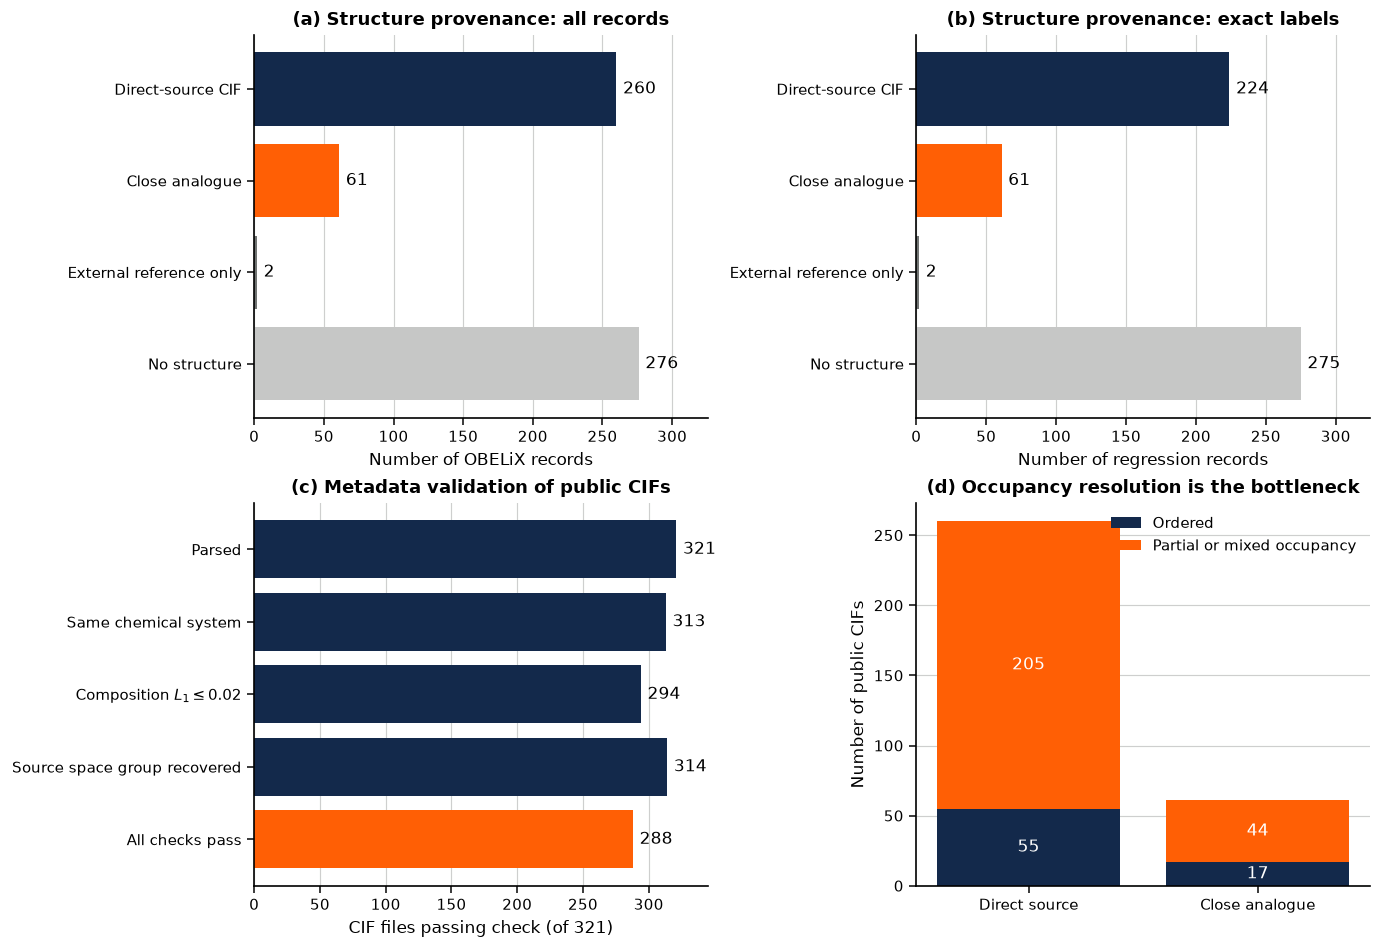

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11.4, 7.8), constrained_layout=True)

relation_order = [
    "direct_source_cif", "close_analogue_cif", "external_reference_only", "no_structure"
]
relation_labels = ["Direct-source CIF", "Close analogue", "External reference only", "No structure"]
relation_colors = [ILLINI_BLUE, ILLINI_ORANGE, ILLINI_STORM, ILLINI_STORM_LIGHT]

# (a) Coverage over all 599 records
all_coverage = structure_manifest["structure_relation"].value_counts().reindex(
    relation_order, fill_value=0
)
bars = axes[0, 0].barh(relation_labels, all_coverage, color=relation_colors)
axes[0, 0].bar_label(bars, padding=4)
axes[0, 0].set_xlim(0, max(all_coverage) * 1.18)
axes[0, 0].invert_yaxis()
axes[0, 0].set_title("(a) Structure provenance: all records")
axes[0, 0].set_xlabel("Number of OBELiX records")
finish_axis(axes[0, 0], "x")

# (b) Coverage for exact conductivity labels
exact_coverage = exact_structure_manifest["structure_relation"].value_counts().reindex(
    relation_order, fill_value=0
)
bars = axes[0, 1].barh(relation_labels, exact_coverage, color=relation_colors)
axes[0, 1].bar_label(bars, padding=4)
axes[0, 1].set_xlim(0, max(exact_coverage) * 1.18)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title("(b) Structure provenance: exact labels")
axes[0, 1].set_xlabel("Number of regression records")
finish_axis(axes[0, 1], "x")

# (c) Independent checks on the 321 public CIFs
validation_counts = pd.Series({
    "Parsed": official_cifs["structure_parse_status"].eq("parsed").sum(),
    "Same chemical system": official_cifs["same_chemical_system"].eq(True).sum(),
    r"Composition $L_1\leq0.02$": official_cifs["tight_composition_flag"].eq(True).sum(),
    "Source space group recovered": official_cifs["space_group_matches_source"].eq(True).sum(),
    "All checks pass": official_cifs["metadata_validation_pass"].sum(),
})
validation_colors = [ILLINI_BLUE] * 4 + [ILLINI_ORANGE]
bars = axes[1, 0].barh(validation_counts.index, validation_counts, color=validation_colors)
axes[1, 0].bar_label(bars, padding=4)
axes[1, 0].set_xlim(0, 345)
axes[1, 0].invert_yaxis()
axes[1, 0].set_title("(c) Metadata validation of public CIFs")
axes[1, 0].set_xlabel("CIF files passing check (of 321)")
finish_axis(axes[1, 0], "x")

# (d) Disorder burden by provenance
occupancy_table = pd.crosstab(
    official_cifs["structure_relation"],
    official_cifs["requires_occupancy_resolution"],
).reindex(["direct_source_cif", "close_analogue_cif"], fill_value=0)
ordered_counts = occupancy_table.get(False, pd.Series(0, index=occupancy_table.index))
disordered_counts = occupancy_table.get(True, pd.Series(0, index=occupancy_table.index))
x_positions = np.arange(2)
axes[1, 1].bar(x_positions, ordered_counts, color=ILLINI_BLUE, label="Ordered")
axes[1, 1].bar(
    x_positions, disordered_counts, bottom=ordered_counts,
    color=ILLINI_ORANGE, label="Partial or mixed occupancy",
)
for index, (ordered, disordered) in enumerate(zip(ordered_counts, disordered_counts)):
    axes[1, 1].text(index, ordered / 2, str(int(ordered)), ha="center", va="center", color="white")
    axes[1, 1].text(
        index, ordered + disordered / 2, str(int(disordered)),
        ha="center", va="center", color="white",
    )
axes[1, 1].set_xticks(x_positions, ["Direct source", "Close analogue"])
axes[1, 1].set_title("(d) Occupancy resolution is the bottleneck")
axes[1, 1].set_ylabel("Number of public CIFs")
axes[1, 1].legend(loc="upper right")
finish_axis(axes[1, 1], "y")

save_report_figure(fig, "figure_04_obelix_structure_manifest.png")
plt.show()


**Figure 4.** Structure provenance and validation before graph learning. Direct-source and close-analogue structures remain separate for both the complete dataset and the exact-label regression subset. All 321 public CIFs parse, while independent composition and symmetry checks identify records requiring manual review. Partial or mixed occupancy is the dominant preprocessing issue and must be resolved transparently before CHGNet embedding.

### Step-1 decision

The structure inventory is now frozen, but graph learning has not started. Only the small set marked `ordered_direct_primary_ready` can enter CHGNet unchanged. Direct-source structures with partial occupancy require a documented representation policy, and close analogues will not be mixed into the primary training cohort.

The next step is Materials Project structure matching. Candidate MP structures will first be restricted by chemical system, composition, and space group, then compared using pymatgen `StructureMatcher` when both structures are available. Matching will remain blind to conductivity, and every accepted MP identifier will retain its matching diagnostics and database version.
